# 05 - Main Models

**IT469 (King Saud University) - NER on Human-Written vs. LLM-Generated News**

## Purpose

This notebook fine-tunes one of the project's three **main NER models** on the silver-labeled data from
`03_silver_labeling.ipynb`, following exactly the same grid-search protocol used to select the annotator in
`02_annotator_selection.ipynb`, and exactly the same 2x2 train/test design, paired bootstrap, and shared
evaluation code (`extract_spans`, `evaluate`, `article_counts`, `paired_bootstrap`) established in
`04_crf_baseline.ipynb`. Three near-identical copies of this notebook exist -- `05_main_models-bert-base-cased.ipynb`,
`05_main_models-roberta-base.ipynb`, `05_main_models-distilbert-base-cased.ipynb` -- differing **only** in the
`MODEL` value of the Configuration cell (Section 1). The fourth model in the project, the linear-chain CRF, is
the baseline built in notebook 04 and is not repeated here.

## Models

| Model / TAG | Hugging Face id | Why |
|---|---|---|
| `bert-base-cased` | `google-bert/bert-base-cased` | Same reference encoder used as an annotator candidate; widely published CoNLL-2003 results [1] |
| `roberta-base` | `FacebookAI/roberta-base` (tokenizer needs `add_prefix_space=True`) | Same parameter budget as BERT-base, stronger pretraining [2] |
| `distilbert-base-cased` | `distilbert/distilbert-base-cased` (cased, NOT the uncased default) | A distilled, ~2x faster encoder [10]; tests whether a smaller model loses much on this task |

## Protocol (identical across models and sides; do not change without team agreement)

| Setting | Value | Source / reason |
|---|---|---|
| Training data | Human side: `human_train_matched.jsonl` (token-count-matched to the LLM side) + `human_validation.jsonl`. LLM side: `llm_train.jsonl` + `llm_validation.jsonl`. Tests: `human_test.jsonl`, `llm_test.jsonl` | Holding training text volume fixed isolates the effect of who wrote the text, same design as notebook 04 |
| Expected article counts | train 2,315 / validation 286 / test 290 (human union llm article ids per split) | Notebook 01's real Colab split, re-verified here independently |
| Label scheme | 9 IOB2 labels, ids 0-8: `O`, `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`, `B-MISC`, `I-MISC` | Same scheme as notebooks 02/03/04 |
| Subword labeling | Label on the first subword of each word; other subwords and special tokens get `-100` | Devlin et al. (2019) [1], same as notebook 02 |
| Output layer | Standard token classification head, no CRF | Devlin et al. (2019) [1] |
| Casing | Cased models only | Capitalization is a key NER cue |
| Grid: learning rate | {1e-5, 2e-5, 3e-5} | Liu et al. (2019), RoBERTa Sec 5.1 [2] |
| Grid: effective batch size | {16, 32} (per-device cap 16; batch 32 = 16 x grad-accum 2) | Liu et al. (2019), RoBERTa Sec 5.1 [2] |
| Max epochs | 10 | RoBERTa Sec 5.1 [2] |
| Early stopping | Validation entity-level micro F1, patience 3 | RoBERTa [2] for early stop on the dev metric; patience 3 is the team's practical choice |
| Best epoch | Restore the epoch with the best validation F1 | `load_best_model_at_end=True` |
| Warmup + schedule | Linear warmup over first 6% of steps, then linear decay to 0 | RoBERTa Sec 5.1 [2]; warmup sized against the full 10-epoch schedule regardless of early stopping |
| Optimizer | AdamW | Loshchilov and Hutter (2019) [5] |
| Weight decay | 0.1 | RoBERTa, Table 10 [2] |
| Dropout | 0.1 (model default) | BERT [1] / RoBERTa [2] |
| Gradient clipping | max norm 1.0 | Transformers [7] default |
| Precision | fp16 mixed precision (CUDA GPU required) | Micikevicius et al. (2018) [6] |
| Max sequence length | 256 subword tokens; training truncates at this length (oversized sentences reported, see Section 5); inference never truncates -- it chunks instead (Section 7), reusing notebook 03's fixed chunking logic | CLAUDE.md Stage 1 protocol; prediction integrity requires no silent token loss |
| Seed | 42 (Python, NumPy, PyTorch, `transformers.set_seed`) | Team decision; GPU training is still not fully deterministic even so |
| Evaluation | Entity-level precision/recall/micro-F1 (+ per-type F1, macro F1) via `seqeval` [9], default (conlleval-compatible) mode | Standard CoNLL evaluation, same as notebooks 02/04 |
| Selection | Per side: config with highest **validation** micro F1 on that side's own validation set. Test sets are never used for any decision | Same rule as notebooks 02/04 |
| Confidence intervals | Paired bootstrap over TEST ARTICLES: 1,000 resamples, seed 42, 95% percentile intervals, one shared article resample across all 4 comparisons | Same code as notebook 04 Section 6, reused verbatim |

## The 2x2 design and the four bootstrap comparisons

Each side (human, LLM) is a separately grid-searched model; each side's best model is evaluated on BOTH test
sets, giving four (trained, tested) cells -- the same design as notebook 04's CRF baseline, so the two are
directly comparable. The four paired-bootstrap comparisons:

1. On **human test**: human-trained minus LLM-trained F1 -- does training on human text help on human text?
2. On **LLM test**: human-trained minus LLM-trained F1 -- does training source matter on LLM text?
3. **Human-trained** model: human test minus LLM test F1 -- does it transfer worse to LLM text?
4. **LLM-trained** model: human test minus LLM test F1 -- does it transfer worse to human text?

A difference is "reliable" if its 95% interval excludes zero.

## Limitation, stated plainly

Every score in this notebook measures agreement with the **silver labels** from notebook 03, not accuracy
against human-annotated ground truth on these news articles -- there is no such ground truth. The annotator's
own CoNLL-2003 test F1 (**0.9273**, `roberta-large`, see notebook 02) is the only available proxy for how
trustworthy those silver labels are. Each model below is trained with a single fixed seed (42); the reported
numbers are a single run, not a distribution over seeds.

## What gets saved, and where

Everything lives under the same shared Drive folder as notebooks 01-04: `ROOT = /content/drive/MyDrive/IT469-NER-Project`.
Per-epoch training checkpoints go to **local Colab disk only** (never Drive) and are deleted after each config:

```
/content/local_main_runs/{TAG}/{side}/{config}/        # local disk only, deleted after each config

ROOT/
├── data/silver/                                              # inputs, shared with notebooks 03/04
├── checkpoints/main/{TAG}/{side}/best/                       # best model + tokenizer per side (no optimizer state)
├── results/main/{TAG}/configs/{side}_{config}.json           # one per finished grid config (resume marker)
├── results/main/{TAG}/configs/{side}_{config}_history.csv    # per-epoch train/val metrics
├── results/main/{TAG}/configs/{side}_best_marker.json        # internal: running best-so-far val F1 (resumability)
├── results/main/{TAG}/grid_summary.csv
├── results/main/{TAG}/best_configs.json                      # {"human": {...}, "llm": {...}}
├── results/main/{TAG}/val_predictions/{side}.jsonl
├── results/main/{TAG}/predictions/{TAG}_{trained}_on_{tested}.jsonl   # sent_id, article_id, predicted_tags
├── results/main/{TAG}/{TAG}_{trained}_on_{tested}.json       # 4 files, one per 2x2 cell
├── results/main/{TAG}/results_2x2.csv, per_type_f1.csv, bootstrap_ci.csv
├── results/main/{TAG}/per_topic_f1.csv, per_topic_origin_gap.csv, per_type_origin_gap.csv
├── results/main/{TAG}/confusion_matrices/*.csv
├── results/main/{TAG}/figures/*.png
├── results/main/{TAG}/environment.json, run_log.txt
└── results/_smoke/main/{TAG}/, checkpoints/_smoke/main/{TAG}/          # smoke-test outputs only
```

## Prerequisites

1. **GPU runtime.** Runtime > Change runtime type > T4 GPU. The notebook stops with a clear error if no CUDA
   GPU is visible.
2. **Drive shortcut** to the shared `IT469-NER-Project` folder, same as notebooks 01-04.
3. Notebook 03 (silver labeling) must have finished -- this notebook reads `data/silver/*.jsonl` only, never
   retrains or relabels anything.

## How to run

1. Edit **only** the Configuration cell (Section 1). `SIDES_TO_RUN` lets you train one side on this Colab
   account/Drive and the other side on a teammate's -- both write into the same shared `{TAG}` folders without
   colliding, since each config/model file is namespaced by `{side}`. Leave `SMOKE_TEST = True` first.
2. Runtime > Run all. The smoke test trains one tiny config for one epoch on a small sample, for whichever
   side(s) are in `SIDES_TO_RUN`, and exercises every figure/CSV/confusion-matrix code path on that small
   sample before printing "Smoke test passed."
3. Set `SMOKE_TEST = False`, Run all again for the real 6-config-per-side grid search. Expect roughly **20-40
   minutes per config on a T4** for `bert-base-cased`/`distilbert-base-cased` (faster for the latter) and
   somewhat longer for `roberta-base`, i.e. **2-5 hours for one side's full grid**; `distilbert-base-cased` is
   noticeably faster end to end. Early stopping (patience 3) usually cuts this well short of 10 epochs.
4. The 2x2 test evaluation (Section 13 onward) only runs once **both** sides have a finished best model on
   Drive -- otherwise it prints exactly what is missing and stops cleanly, so it is safe to run this notebook
   with `SIDES_TO_RUN = ["human"]` today and `["llm"]` tomorrow (or on another account) without errors.
5. Safe to disconnect and rerun at any point: finished configs, the per-side best-model reload check, and each
   2x2 test-evaluation cell all skip once done, unless `FORCE_REBUILD = True`.

## References

In-text citations `[1]`-`[11]` point to the numbered list in the last section of this notebook.


## 1. Configuration


In [3]:
# Configuration: model choice, smoke/rebuild switches, which sides to run, and every protocol constant.

MODEL = "roberta-base"   # one of: "bert-base-cased", "roberta-base", "distilbert-base-cased"
SMOKE_TEST = False                  # True = fast pipeline check only; set False to run the real grid search
FORCE_REBUILD = False               # True = ignore existing finished outputs and redo them
SIDES_TO_RUN = ["human", "llm"]     # subset of ["human", "llm"] -- run the rest on another Colab account/Drive

# --- fixed protocol constants (do not change; see Section 0 for sources) ---
MODEL_TO_HF_ID = {
    "bert-base-cased": "google-bert/bert-base-cased",
    "roberta-base": "FacebookAI/roberta-base",
    "distilbert-base-cased": "distilbert/distilbert-base-cased",
}
assert MODEL in MODEL_TO_HF_ID, f"MODEL must be one of {list(MODEL_TO_HF_ID)}, got {MODEL!r}"
assert SIDES_TO_RUN and set(SIDES_TO_RUN) <= {"human", "llm"}, (
    f"SIDES_TO_RUN must be a non-empty subset of ['human', 'llm'], got {SIDES_TO_RUN}"
)
MODEL_ID = MODEL_TO_HF_ID[MODEL]
TAG = MODEL  # alias matching the Drive-path naming convention used throughout this notebook
IS_ROBERTA = "roberta" in MODEL  # RoBERTa's tokenizer needs add_prefix_space=True with pre-split tokens

LABEL_NAMES = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]
ID2LABEL = {i: name for i, name in enumerate(LABEL_NAMES)}
LABEL2ID = {name: i for i, name in enumerate(LABEL_NAMES)}

EXPECTED_ARTICLE_COUNTS = {"train": 2315, "validation": 286, "test": 290}

LEARNING_RATES = [1e-5, 2e-5, 3e-5]        # RoBERTa paper, Sec 5.1
BATCH_SIZES = [16, 32]                      # effective (post grad-accum) batch size
MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3
WEIGHT_DECAY = 0.1
WARMUP_FRACTION = 0.06
MAX_SEQ_LENGTH = 256
SEED = 42
MAX_PER_DEVICE_BATCH = 16                   # grad accumulation covers effective batch size 32

N_BOOTSTRAP = 1000
CODE_CHECK_TOLERANCE = 0.002                # reload-vs-recorded validation F1 tolerance (same value notebook 03 used)
INFERENCE_BATCH_SIZE = 64                   # notebook 03's labeling batch size

SMOKE_N_TRAIN = 200          # smoke test: training sentences per side
SMOKE_N_VAL = 100            # smoke test: validation sentences per side
SMOKE_N_TEST_ARTICLES = 20   # smoke test: shared test articles kept for the 2x2 evaluation
SMOKE_EPOCHS = 1

print("Active configuration")
print("---------------------")
print(f"MODEL                 : {MODEL}")
print(f"MODEL_ID              : {MODEL_ID}")
print(f"IS_ROBERTA            : {IS_ROBERTA}")
print(f"SIDES_TO_RUN          : {SIDES_TO_RUN}")
print(f"SMOKE_TEST            : {SMOKE_TEST}")
print(f"FORCE_REBUILD         : {FORCE_REBUILD}")
print(f"LEARNING_RATES        : {LEARNING_RATES}")
print(f"BATCH_SIZES (eff.)    : {BATCH_SIZES}")
print(f"MAX_EPOCHS            : {MAX_EPOCHS}")
print(f"EARLY_STOPPING_PATIENCE: {EARLY_STOPPING_PATIENCE}")
print(f"MAX_SEQ_LENGTH        : {MAX_SEQ_LENGTH}")
print(f"SEED                  : {SEED}")
print(f"Number of grid configs per side: {len(LEARNING_RATES) * len(BATCH_SIZES)}")


Active configuration
---------------------
MODEL                 : roberta-base
MODEL_ID              : FacebookAI/roberta-base
IS_ROBERTA            : True
SIDES_TO_RUN          : ['human', 'llm']
SMOKE_TEST            : False
FORCE_REBUILD         : False
LEARNING_RATES        : [1e-05, 2e-05, 3e-05]
BATCH_SIZES (eff.)    : [16, 32]
MAX_EPOCHS            : 10
EARLY_STOPPING_PATIENCE: 3
MAX_SEQ_LENGTH        : 256
SEED                  : 42
Number of grid configs per side: 6


## 2. Setup


In [4]:
!pip install -q -U pip wheel "setuptools<82"


In [5]:
# Setup: install only what Colab is missing. seqeval is never preinstalled; datasets/accelerate usually are,
# so we avoid reinstalling them (that can pull in versions that don't match Colab's preinstalled torch).
# setuptools>=82 is pinned below 82 above because newer setuptools breaks seqeval's build, but torch/transformers
# are deliberately left unpinned -- their exact Colab-preinstalled versions are recorded in environment.json.
!pip install -q seqeval

import importlib
import subprocess
import sys

def _ensure_installed(import_name, pip_name=None):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])

_ensure_installed("datasets")
_ensure_installed("accelerate")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
# Imports used throughout the notebook.
import contextlib
import gc
import importlib.metadata
import json
import logging
import math
import platform
import random
import shutil
import time
import traceback
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import datasets
import transformers
import accelerate
from datasets import Dataset
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import confusion_matrix
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    TrainerCallback,
    EarlyStoppingCallback,
    set_seed,
)


In [7]:
# Require a current Transformers API (eval_strategy / processing_class, matching notebooks 02/03) and a CUDA
# GPU: fp16 training depends on it, and inference also runs faster/under autocast with one available.
_tf_version_parts = tuple(int(p) for p in transformers.__version__.split(".")[:2])
assert _tf_version_parts >= (4, 46), (
    f"This notebook requires transformers >= 4.46 (found {transformers.__version__}). "
    "Restart the runtime after `pip install -U transformers` if Colab's preinstalled version is older."
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab: Runtime > Change runtime type > T4 GPU, "
        "then Runtime > Run all again."
    )
device = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
print(f"GPU detected: {GPU_NAME}")

# Fix every source of randomness we control. GPU training is still not fully deterministic
# (non-deterministic cuDNN kernels), so exact bit-for-bit reproduction is not expected even so.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

ENV_INFO = {
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "datasets_version": datasets.__version__,
    "accelerate_version": accelerate.__version__,
    "seqeval_version": importlib.metadata.version("seqeval"),
    "gpu_name": GPU_NAME,
    "model": MODEL,
    "model_id": MODEL_ID,
    "sides_to_run": SIDES_TO_RUN,
    "smoke_test": SMOKE_TEST,
}
print(json.dumps(ENV_INFO, indent=2))


GPU detected: NVIDIA L4
{
  "date_utc": "2026-11-09T04:58:36.821457+00:00",
  "python_version": "3.13.16",
  "torch_version": "2.14.1+cu130",
  "transformers_version": "5.22.1",
  "datasets_version": "4.8.5",
  "accelerate_version": "1.15.0",
  "seqeval_version": "1.2.2",
  "gpu_name": "NVIDIA L4",
  "model": "roberta-base",
  "model_id": "FacebookAI/roberta-base",
  "sides_to_run": [
    "human",
    "llm"
  ],
  "smoke_test": false
}


## 3. Mount Drive and paths


In [8]:
# Mount Drive and locate the shared project folder (same ROOT as notebooks 01-04).
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/IT469-NER-Project")
if not ROOT.exists():
    raise RuntimeError(
        f"{ROOT} does not exist. Add the shared folder as a shortcut in your own My Drive: "
        "Google Drive > Shared with me > IT469-NER-Project > (right-click) Organize > "
        "Add shortcut > My Drive. Then re-run this cell."
    )
print(f"ROOT resolved: {ROOT}")


Mounted at /content/drive
ROOT resolved: /content/drive/MyDrive/IT469-NER-Project


In [9]:
# Resolve every other path from ROOT. Inputs (silver sentence files) are shared and real regardless of
# SMOKE_TEST; only this notebook's own outputs (and the local-disk training checkpoints) redirect under
# SMOKE_TEST. Per-epoch Trainer checkpoints NEVER go to Drive -- only to local Colab disk -- per the
# local-disk-full lesson learned in notebook 02.
SILVER_DIR = ROOT / "data" / "silver"
SILVER_PATHS = {
    ("human", "train"): SILVER_DIR / "human_train_matched.jsonl",
    ("llm", "train"): SILVER_DIR / "llm_train.jsonl",
    ("human", "validation"): SILVER_DIR / "human_validation.jsonl",
    ("llm", "validation"): SILVER_DIR / "llm_validation.jsonl",
    ("human", "test"): SILVER_DIR / "human_test.jsonl",
    ("llm", "test"): SILVER_DIR / "llm_test.jsonl",
}

if SMOKE_TEST:
    RESULTS_DIR = ROOT / "results" / "_smoke" / "main" / TAG
    CKPT_DIR = ROOT / "checkpoints" / "_smoke" / "main" / TAG
else:
    RESULTS_DIR = ROOT / "results" / "main" / TAG
    CKPT_DIR = ROOT / "checkpoints" / "main" / TAG

CONFIGS_DIR = RESULTS_DIR / "configs"
VAL_PREDICTIONS_DIR = RESULTS_DIR / "val_predictions"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"
CONFUSION_DIR = RESULTS_DIR / "confusion_matrices"
FIGURES_DIR = RESULTS_DIR / "figures"

GRID_SUMMARY_CSV = RESULTS_DIR / "grid_summary.csv"
BEST_CONFIGS_JSON = RESULTS_DIR / "best_configs.json"
RESULTS_2X2_CSV = RESULTS_DIR / "results_2x2.csv"
PER_TYPE_F1_CSV = RESULTS_DIR / "per_type_f1.csv"
BOOTSTRAP_CI_CSV = RESULTS_DIR / "bootstrap_ci.csv"
PER_TOPIC_F1_CSV = RESULTS_DIR / "per_topic_f1.csv"
PER_TOPIC_ORIGIN_GAP_CSV = RESULTS_DIR / "per_topic_origin_gap.csv"
PER_TYPE_ORIGIN_GAP_CSV = RESULTS_DIR / "per_type_origin_gap.csv"
ENVIRONMENT_JSON = RESULTS_DIR / "environment.json"
RUN_LOG_TXT = RESULTS_DIR / "run_log.txt"

# Local disk only -- never Drive -- for per-epoch Trainer checkpoints. Deleted after each config.
LOCAL_RUNS_ROOT = Path("/content/local_main_runs") / TAG

for d in [RESULTS_DIR, CONFIGS_DIR, VAL_PREDICTIONS_DIR, PREDICTIONS_DIR, CONFUSION_DIR, FIGURES_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"RESULTS_DIR     : {RESULTS_DIR}")
print(f"CKPT_DIR        : {CKPT_DIR}")
print(f"LOCAL_RUNS_ROOT  : {LOCAL_RUNS_ROOT} (local disk, never Drive)")


RESULTS_DIR     : /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base
CKPT_DIR        : /content/drive/MyDrive/IT469-NER-Project/checkpoints/main/roberta-base
LOCAL_RUNS_ROOT  : /content/local_main_runs/roberta-base (local disk, never Drive)


In [10]:
# Logger that writes to run_log.txt (appended, so it survives disconnects) AND prints to the cell output.
logger = logging.getLogger(f"main_{TAG}_{'smoke' if SMOKE_TEST else 'full'}")
logger.setLevel(logging.INFO)
logger.handlers.clear()  # avoid duplicate handlers if this cell is re-run

_formatter = logging.Formatter("%(asctime)s [%(levelname)s] %(message)s")

_file_handler = logging.FileHandler(RUN_LOG_TXT, mode="a", encoding="utf-8")
_file_handler.setFormatter(_formatter)
logger.addHandler(_file_handler)

_stream_handler = logging.StreamHandler()
_stream_handler.setFormatter(_formatter)
logger.addHandler(_stream_handler)


def save_json(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def load_jsonl(path):
    # Copied verbatim from notebook 04 Section 6 (its own comment there anticipates this reuse).
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def write_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record) + "\n")


save_json(ENV_INFO, ENVIRONMENT_JSON)
logger.info(f"Session started. model={MODEL} sides_to_run={SIDES_TO_RUN} smoke_test={SMOKE_TEST} root={ROOT}")
logger.info(f"Environment: {ENV_INFO}")


2026-11-09 04:59:05,142 [INFO] Session started. model=roberta-base sides_to_run=['human', 'llm'] smoke_test=False root=/content/drive/MyDrive/IT469-NER-Project
INFO:main_roberta-base_full:Session started. model=roberta-base sides_to_run=['human', 'llm'] smoke_test=False root=/content/drive/MyDrive/IT469-NER-Project
2026-11-09 04:59:05,719 [INFO] Environment: {'date_utc': '2026-11-09T04:58:36.821457+00:00', 'python_version': '3.13.16', 'torch_version': '2.14.1+cu130', 'transformers_version': '5.22.1', 'datasets_version': '4.8.5', 'accelerate_version': '1.15.0', 'seqeval_version': '1.2.2', 'gpu_name': 'NVIDIA L4', 'model': 'roberta-base', 'model_id': 'FacebookAI/roberta-base', 'sides_to_run': ['human', 'llm'], 'smoke_test': False}
INFO:main_roberta-base_full:Environment: {'date_utc': '2026-11-09T04:58:36.821457+00:00', 'python_version': '3.13.16', 'torch_version': '2.14.1+cu130', 'transformers_version': '5.22.1', 'datasets_version': '4.8.5', 'accelerate_version': '1.15.0', 'seqeval_versi

## 4. Load silver data + checks


In [11]:
# Load all six silver files once (human side's "train" key is the token-count-matched file, same convention
# as notebook 04's SILVER_PATHS).
silver = {key: load_jsonl(path) for key, path in SILVER_PATHS.items()}
for (side, split), records in silver.items():
    assert records, f"{side}_{split} is empty: {SILVER_PATHS[(side, split)]}"
    logger.info(f"Loaded {side}_{split}: {len(records)} sentences")


2026-11-09 04:59:12,405 [INFO] Loaded human_train: 55394 sentences
INFO:main_roberta-base_full:Loaded human_train: 55394 sentences
2026-11-09 04:59:12,407 [INFO] Loaded llm_train: 50521 sentences
INFO:main_roberta-base_full:Loaded llm_train: 50521 sentences
2026-11-09 04:59:12,408 [INFO] Loaded human_validation: 9060 sentences
INFO:main_roberta-base_full:Loaded human_validation: 9060 sentences
2026-11-09 04:59:12,410 [INFO] Loaded llm_validation: 6221 sentences
INFO:main_roberta-base_full:Loaded llm_validation: 6221 sentences
2026-11-09 04:59:12,411 [INFO] Loaded human_test: 9132 sentences
INFO:main_roberta-base_full:Loaded human_test: 9132 sentences
2026-11-09 04:59:12,412 [INFO] Loaded llm_test: 6265 sentences
INFO:main_roberta-base_full:Loaded llm_test: 6265 sentences


In [12]:
# Assertions: tags/tokens align and are valid, and both test sets cover the SAME articles (the paired
# bootstrap resamples one shared list of article ids and applies it to both test sets). Identical to
# notebook 04 Section 4.
VALID_TAGS = set(LABEL_NAMES)

for (side, split), records in silver.items():
    for rec in records:
        assert len(rec["tokens"]) == len(rec["ner_tags"]), (
            f"{side}_{split} {rec['sent_id']}: {len(rec['tokens'])} tokens but {len(rec['ner_tags'])} tags"
        )
        _bad_tags = set(rec["ner_tags"]) - VALID_TAGS
        assert not _bad_tags, f"{side}_{split} {rec['sent_id']}: invalid tag(s) {_bad_tags}"

human_test_articles = {r["article_id"] for r in silver[("human", "test")]}
llm_test_articles = {r["article_id"] for r in silver[("llm", "test")]}
assert human_test_articles == llm_test_articles, (
    f"human_test and llm_test must cover the same articles for the paired bootstrap -- "
    f"{len(human_test_articles - llm_test_articles)} article(s) only in human_test, "
    f"{len(llm_test_articles - human_test_articles)} article(s) only in llm_test"
)
logger.info(f"Checks OK: all tags/tokens aligned and valid; {len(human_test_articles)} shared test articles")


2026-11-09 04:59:12,617 [INFO] Checks OK: all tags/tokens aligned and valid; 290 shared test articles
INFO:main_roberta-base_full:Checks OK: all tags/tokens aligned and valid; 290 shared test articles


In [13]:
# Article-id disjointness across train/validation/test (notebook 04 Section 13.1, re-verified here
# independently), plus the expected-count assertion from the spec.
_split_articles = {}
for split in ["train", "validation", "test"]:
    _split_articles[split] = {r["article_id"] for r in silver[("human", split)]} | {
        r["article_id"] for r in silver[("llm", split)]
    }

_overlap_train_val = _split_articles["train"] & _split_articles["validation"]
_overlap_train_test = _split_articles["train"] & _split_articles["test"]
_overlap_val_test = _split_articles["validation"] & _split_articles["test"]
assert not _overlap_train_val, f"{len(_overlap_train_val)} article(s) in both train and validation"
assert not _overlap_train_test, f"{len(_overlap_train_test)} article(s) in both train and test"
assert not _overlap_val_test, f"{len(_overlap_val_test)} article(s) in both validation and test"

if not SMOKE_TEST:
    for split, expected in EXPECTED_ARTICLE_COUNTS.items():
        actual = len(_split_articles[split])
        assert actual == expected, f"{split}: expected {expected} articles, found {actual}"

logger.info(
    f"Disjointness OK: 0 shared article ids across train ({len(_split_articles['train'])}) / "
    f"validation ({len(_split_articles['validation'])}) / test ({len(_split_articles['test'])})"
)
print("No article-id overlap between train, validation, and test; counts match the expected 2,315 / 286 / 290.")


2026-11-09 04:59:12,654 [INFO] Disjointness OK: 0 shared article ids across train (2315) / validation (286) / test (290)
INFO:main_roberta-base_full:Disjointness OK: 0 shared article ids across train (2315) / validation (286) / test (290)


No article-id overlap between train, validation, and test; counts match the expected 2,315 / 286 / 290.


In [14]:
# Display sentence/token/entity counts per file, for a quick sanity look (mirrors notebook 04 Section 4).
def _count_entities(records):
    n = 0
    for r in records:
        n += sum(1 for t in r["ner_tags"] if t.startswith("B-"))
    return n


_overview_rows = [
    {
        "side": side, "split": split,
        "sentences": len(records),
        "tokens": sum(len(r["tokens"]) for r in records),
        "entities": _count_entities(records),
    }
    for (side, split), records in silver.items()
]
display(pd.DataFrame(_overview_rows))


,side,split,sentences,tokens,entities
0,human,train,55394,1342507,91180
1,llm,train,50521,1342562,71947
2,human,validation,9060,219427,14530
3,llm,validation,6221,168119,8681
4,human,test,9132,217464,14526
5,llm,test,6265,167623,8878


In [15]:
# Smoke-test shrink: applied AFTER the real-scale checks above, so those always reflect the true full
# dataset. Shrinks train/validation per side and keeps only a small shared slice of test articles.
if SMOKE_TEST:
    for side in ["human", "llm"]:
        silver[(side, "train")] = silver[(side, "train")][:SMOKE_N_TRAIN]
        silver[(side, "validation")] = silver[(side, "validation")][:SMOKE_N_VAL]

    _smoke_test_articles = set(sorted(human_test_articles)[:SMOKE_N_TEST_ARTICLES])
    for side in ["human", "llm"]:
        silver[(side, "test")] = [r for r in silver[(side, "test")] if r["article_id"] in _smoke_test_articles]

    logger.info(
        f"SMOKE_TEST: train={len(silver[('human','train')])}/{len(silver[('llm','train')])} (human/llm), "
        f"val={len(silver[('human','validation')])}/{len(silver[('llm','validation')])}, "
        f"test_articles={len(_smoke_test_articles)}"
    )


## 5. Tokenizer and oversized-sentence report


In [16]:
# RoBERTa's BPE tokenizer needs add_prefix_space=True to tokenize pre-split word lists correctly.
if IS_ROBERTA:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, add_prefix_space=True)
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
print(f"Loaded tokenizer: {tokenizer.__class__.__name__} (add_prefix_space={IS_ROBERTA})")


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded tokenizer: RobertaTokenizer (add_prefix_space=True)


In [17]:
# Report (not assert) how many sentences exceed the 256-subword budget per side/split, for this tokenizer.
# Training truncates at MAX_SEQ_LENGTH (same protocol as notebook 02); inference never truncates -- it
# chunks instead (Section 7) -- so this is a diagnostic, not a hard requirement, unlike notebook 02's CoNLL
# check (news sentences are not guaranteed as short as CoNLL's, even though in practice notebook 03 found
# zero oversized sentences in this exact corpus with the same 256-token budget).
def count_oversized_sentences(records, max_len=MAX_SEQ_LENGTH):
    n_over, example_ids = 0, []
    for r in records:
        length = len(tokenizer(r["tokens"], is_split_into_words=True, add_special_tokens=True)["input_ids"])
        if length > max_len:
            n_over += 1
            if len(example_ids) < 5:
                example_ids.append(r["sent_id"])
    return n_over, example_ids


oversized_rows = []
for (side, split), records in silver.items():
    n_over, examples = count_oversized_sentences(records)
    oversized_rows.append({"side": side, "split": split, "n_sentences": len(records), "n_oversized": n_over})
    if n_over:
        logger.warning(f"{side}_{split}: {n_over} sentence(s) exceed {MAX_SEQ_LENGTH} subwords, e.g. {examples}")
oversized_df = pd.DataFrame(oversized_rows)
display(oversized_df)
logger.info(f"Oversized-sentence report (tokenizer={MODEL}): total oversized = {oversized_df['n_oversized'].sum()}")


,side,split,n_sentences,n_oversized
0,human,train,55394,0
1,llm,train,50521,0
2,human,validation,9060,0
3,llm,validation,6221,0
4,human,test,9132,0
5,llm,test,6265,0


2026-11-09 04:59:45,779 [INFO] Oversized-sentence report (tokenizer=roberta-base): total oversized = 0
INFO:main_roberta-base_full:Oversized-sentence report (tokenizer=roberta-base): total oversized = 0


## 6. Tokenization and label alignment (training)


In [18]:
# Tokenize and align labels for training: each word's label goes on its first subword; other subwords and
# special tokens get -100. Silver files store STRING tags (already BIO-repaired by notebook 03), so they
# are converted to ids via LABEL2ID before alignment -- the one real difference from notebook 02, whose
# CoNLL-2003 source already stored integer ids.
def tokenize_and_align_labels(examples):
    tokenized = tokenizer(
        examples["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_SEQ_LENGTH,
    )
    all_labels = []
    for i, tags in enumerate(examples["ner_tags"]):
        tag_ids = [LABEL2ID[t] for t in tags]
        word_ids = tokenized.word_ids(batch_index=i)
        labels, prev_word_id = [], None
        for word_id in word_ids:
            if word_id is None:
                labels.append(-100)
            elif word_id != prev_word_id:
                labels.append(tag_ids[word_id])
            else:
                labels.append(-100)
            prev_word_id = word_id
        all_labels.append(labels)
    tokenized["labels"] = all_labels
    return tokenized


raw_ds, tokenized_ds = {}, {}
for side in ["human", "llm"]:
    for split in ["train", "validation"]:
        raw_ds[(side, split)] = Dataset.from_list(silver[(side, split)])
        tokenized_ds[(side, split)] = raw_ds[(side, split)].map(
            tokenize_and_align_labels, batched=True, remove_columns=raw_ds[(side, split)].column_names
        )
    logger.info(
        f"{side}: tokenized train={len(tokenized_ds[(side, 'train')])} "
        f"validation={len(tokenized_ds[(side, 'validation')])}"
    )

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)


Map:   0%|          | 0/55394 [00:00<?, ? examples/s]

Map:   0%|          | 0/9060 [00:00<?, ? examples/s]

2026-11-09 04:59:53,465 [INFO] human: tokenized train=55394 validation=9060
INFO:main_roberta-base_full:human: tokenized train=55394 validation=9060


Map:   0%|          | 0/50521 [00:00<?, ? examples/s]

Map:   0%|          | 0/6221 [00:00<?, ? examples/s]

2026-11-09 05:00:01,204 [INFO] llm: tokenized train=50521 validation=6221
INFO:main_roberta-base_full:llm: tokenized train=50521 validation=6221


In [19]:
# Visually confirm the alignment on one example: word | subword tokens | label.
_example_side = SIDES_TO_RUN[0]
_example = raw_ds[(_example_side, "train")][0]
_enc = tokenizer(_example["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_SEQ_LENGTH)
_word_ids = _enc.word_ids()
_sub_tokens = tokenizer.convert_ids_to_tokens(_enc["input_ids"])
for tok, wid in zip(_sub_tokens, _word_ids):
    label = _example["ner_tags"][wid] if wid is not None else "-"
    print(f"{tok:>15}  word_id={wid!s:>4}  label={label}")


            <s>  word_id=None  label=-
             Ġ(  word_id=   0  label=O
           ĠSee  word_id=   1  label=O
           ĠThe  word_id=   2  label=B-ORG
          ĠDead  word_id=   3  label=I-ORG
       ĠWeather  word_id=   4  label=I-ORG
             Ġ'  word_id=   5  label=O
              s  word_id=   5  label=O
         Ġvideo  word_id=   6  label=O
           Ġfor  word_id=   7  label=O
          ĠWill  word_id=   8  label=O
         ĠThere  word_id=   9  label=O
            ĠBe  word_id=  10  label=O
        ĠEnough  word_id=  11  label=O
         ĠWater  word_id=  12  label=O
             Ġ?  word_id=  13  label=O
           </s>  word_id=None  label=-


## 7. Chunked, length-safe inference engine

Training truncates at `MAX_SEQ_LENGTH` (Section 6, same as notebook 02's protocol). Inference never does:
every prediction list must come out exactly as long as its gold token list, with no token silently dropped.
`chunk_sentence_word_ranges` and the chunking logic inside `predict_tags_for_sentences` below are reused
from notebook 03's fixed labeling pipeline (`chunk_sentence_word_ranges` / `label_sentences`), with one
change -- a word that happens to yield zero subwords (an extremely rare tokenizer edge case) is assigned
`"O"` and counted/logged, instead of failing an assertion, per the project's prediction-integrity
requirement.


In [20]:
# Chunk a long sentence into word-index ranges that each fit the model's subword budget, preferring to cut
# right after a comma/semicolon/colon in the second half of an over-long chunk. Copied from notebook 03
# Section 5 (chunk_sentence_word_ranges), parameterized on this notebook's tokenizer/MAX_SEQ_LENGTH.
def chunk_sentence_word_ranges(tokens, max_len=MAX_SEQ_LENGTH):
    if not tokens:
        return [(0, 0)]
    encoded = tokenizer(tokens, is_split_into_words=True, add_special_tokens=False)
    word_ids = encoded.word_ids()
    subwords_per_word = [0] * len(tokens)
    for wid in word_ids:
        if wid is not None:
            subwords_per_word[wid] += 1

    budget = max_len - 2  # reserve 2 positions for special tokens
    chunks = []
    start = 0
    n = len(tokens)
    while start < n:
        cum, end = 0, start
        while end < n and cum + subwords_per_word[end] <= budget:
            cum += subwords_per_word[end]
            end += 1
        if end == start:
            end = start + 1  # a single word alone exceeds the budget (very rare); take it anyway to progress

        if end < n:
            half = start + (end - start) // 2
            cut = end
            for idx in range(end - 1, max(half, start) - 1, -1):
                stripped = tokens[idx].rstrip()
                if stripped and stripped[-1] in ",;:":
                    cut = idx + 1
                    break
        else:
            cut = end
        chunks.append((start, cut))
        start = cut
    return chunks


In [21]:
# Chunked, length-safe inference: batches by subword length for efficient padding, runs under fp16 autocast
# and no_grad, takes the first-subword prediction per word, and restores sentence order. Adapted from
# notebook 03's label_sentences; the one behavior change is the "O" fallback for zero-subword words
# (counted and logged) instead of an assertion failure.
def predict_tags_for_sentences(model, token_lists, batch_size=INFERENCE_BATCH_SIZE, use_fp16=True):
    units = []  # (sent_idx, token_sublist) -- one per chunk, in per-sentence order
    chunked_flags = [False] * len(token_lists)
    for sent_idx, tokens in enumerate(token_lists):
        ranges = chunk_sentence_word_ranges(tokens)
        chunked_flags[sent_idx] = len(ranges) > 1
        for (s, e) in ranges:
            units.append((sent_idx, tokens[s:e]))

    if not units:
        return [[] for _ in token_lists], chunked_flags, 0

    unit_lengths = [
        len(tokenizer(sub_tokens, is_split_into_words=True, truncation=True, max_length=MAX_SEQ_LENGTH)["input_ids"])
        for _, sub_tokens in units
    ]
    order = sorted(range(len(units)), key=lambda i: unit_lengths[i])

    autocast_ctx = (
        torch.autocast(device_type="cuda", dtype=torch.float16)
        if (device.type == "cuda" and use_fp16) else contextlib.nullcontext()
    )

    unit_tags = [None] * len(units)
    n_zero_subword = 0
    for batch_start in range(0, len(order), batch_size):
        batch_idx = order[batch_start: batch_start + batch_size]
        batch_tokens = [units[i][1] for i in batch_idx]
        encoded = tokenizer(
            batch_tokens, is_split_into_words=True, truncation=True, max_length=MAX_SEQ_LENGTH,
            padding=True, return_tensors="pt",
        )
        model_inputs = {k: v.to(device) for k, v in encoded.items()}
        with torch.no_grad(), autocast_ctx:
            outputs = model(**model_inputs)
        pred_ids = outputs.logits.argmax(dim=-1).cpu().numpy()

        for b, unit_i in enumerate(batch_idx):
            word_ids = encoded.word_ids(batch_index=b)
            sub_tokens = units[unit_i][1]
            tags = [None] * len(sub_tokens)
            prev_word = None
            for pos, wid in enumerate(word_ids):
                if wid is None:
                    continue
                if wid != prev_word:  # first subword of this word only
                    tags[wid] = LABEL_NAMES[pred_ids[b, pos]]
                prev_word = wid
            for wi, t in enumerate(tags):
                if t is None:  # zero-subword word: never silently drop it
                    tags[wi] = "O"
                    n_zero_subword += 1
            unit_tags[unit_i] = tags

    sent_tags = [[] for _ in token_lists]
    for (sent_idx, sub_tokens), tags in zip(units, unit_tags):
        sent_tags[sent_idx].extend(tags)

    for sent_idx, tokens in enumerate(token_lists):
        assert len(sent_tags[sent_idx]) == len(tokens), (
            f"sentence {sent_idx}: got {len(sent_tags[sent_idx])} tags for {len(tokens)} tokens"
        )
    if n_zero_subword:
        logger.warning(f"{n_zero_subword} word(s) yielded zero subwords and were assigned 'O'")
    return sent_tags, chunked_flags, n_zero_subword


## 8. Metrics and shared evaluation code


In [22]:
# compute_metrics for the Trainer's internal eval loop during grid search: converts ids back to label
# strings, drops -100 positions, and returns entity-level micro precision/recall/F1. Same pattern as
# notebook 02. This is what the grid search's config selection is anchored to (truncation-based, matching
# the documented protocol); the robust chunked-inference F1 computed later must reproduce it within
# CODE_CHECK_TOLERANCE (Section 11).
def _predictions_to_label_strings(predictions, labels):
    pred_ids = np.argmax(predictions, axis=2)
    true_label_strs, pred_label_strs = [], []
    for pred_seq, label_seq in zip(pred_ids, labels):
        true_seq, pred_seq_strs = [], []
        for p, l in zip(pred_seq, label_seq):
            if l == -100:
                continue
            true_seq.append(LABEL_NAMES[l])
            pred_seq_strs.append(LABEL_NAMES[p])
        true_label_strs.append(true_seq)
        pred_label_strs.append(pred_seq_strs)
    return true_label_strs, pred_label_strs


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    true_label_strs, pred_label_strs = _predictions_to_label_strings(predictions, labels)
    return {
        "precision": precision_score(true_label_strs, pred_label_strs),
        "recall": recall_score(true_label_strs, pred_label_strs),
        "f1": f1_score(true_label_strs, pred_label_strs),
    }


In [23]:
# BIO span extraction, standard seqeval evaluation, per-article (tp, fp, fn) counts, and the paired
# bootstrap -- copied VERBATIM from notebook 04 Section 6, so notebook 05's 2x2 evaluation and bootstrap
# are byte-for-byte the same code the CRF baseline used (the two results are therefore directly comparable,
# as intended by the project design).
def extract_spans(tags):
    spans = []
    cur_type, cur_start = None, None
    for i, tag in enumerate(tags):
        if tag == "O":
            if cur_type is not None:
                spans.append((cur_type, cur_start, i))
                cur_type, cur_start = None, None
        elif tag.startswith("B-"):
            if cur_type is not None:
                spans.append((cur_type, cur_start, i))
            cur_type, cur_start = tag[2:], i
        elif tag.startswith("I-"):
            ent_type = tag[2:]
            if cur_type != ent_type:  # not continuing a matching entity -> starts a new one
                if cur_type is not None:
                    spans.append((cur_type, cur_start, i))
                cur_type, cur_start = ent_type, i
    if cur_type is not None:
        spans.append((cur_type, cur_start, len(tags)))
    return spans


def evaluate(gold_tag_lists, pred_tag_lists):
    report = classification_report(gold_tag_lists, pred_tag_lists, output_dict=True)
    return {
        "precision": precision_score(gold_tag_lists, pred_tag_lists),
        "recall": recall_score(gold_tag_lists, pred_tag_lists),
        "f1": f1_score(gold_tag_lists, pred_tag_lists),
        "macro_f1": report["macro avg"]["f1-score"],
        "report": report,
    }


def article_counts(records, pred_tag_lists):
    counts = defaultdict(lambda: [0, 0, 0])
    for rec, pred_tags in zip(records, pred_tag_lists):
        gold_spans = set(extract_spans(rec["ner_tags"]))
        pred_spans = set(extract_spans(pred_tags))
        c = counts[rec["article_id"]]
        c[0] += len(gold_spans & pred_spans)   # tp
        c[1] += len(pred_spans - gold_spans)   # fp
        c[2] += len(gold_spans - pred_spans)   # fn
    return {aid: tuple(v) for aid, v in counts.items()}


def _micro_f1_from_counts(tp, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0


def paired_bootstrap(counts_by_combo, comparisons, n_bootstrap, seed):
    '''counts_by_combo: {combo_key: {article_id: (tp, fp, fn)}}, all sharing the same article ids.
    comparisons: {name: (combo_key_a, combo_key_b)} -- each reported as a_f1 - b_f1.
    Returns a DataFrame: comparison, observed_difference, ci_low, ci_high, reliable.'''
    article_ids = sorted(next(iter(counts_by_combo.values())).keys())
    n = len(article_ids)
    tp_arr, fp_arr, fn_arr = {}, {}, {}
    for combo, by_article in counts_by_combo.items():
        tp_arr[combo] = np.array([by_article[aid][0] for aid in article_ids], dtype=np.int64)
        fp_arr[combo] = np.array([by_article[aid][1] for aid in article_ids], dtype=np.int64)
        fn_arr[combo] = np.array([by_article[aid][2] for aid in article_ids], dtype=np.int64)

    observed_f1 = {
        combo: _micro_f1_from_counts(tp_arr[combo].sum(), fp_arr[combo].sum(), fn_arr[combo].sum())
        for combo in counts_by_combo
    }

    rng = np.random.default_rng(seed)
    boot_diffs = {name: np.empty(n_bootstrap) for name in comparisons}
    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)  # one resample of article positions, shared across all combos
        f1_this_draw = {
            combo: _micro_f1_from_counts(tp_arr[combo][idx].sum(), fp_arr[combo][idx].sum(), fn_arr[combo][idx].sum())
            for combo in counts_by_combo
        }
        for name, (a, c) in comparisons.items():
            boot_diffs[name][b] = f1_this_draw[a] - f1_this_draw[c]

    rows = []
    for name, (a, c) in comparisons.items():
        observed_diff = observed_f1[a] - observed_f1[c]
        ci_low, ci_high = np.percentile(boot_diffs[name], [2.5, 97.5])
        rows.append({
            "comparison": name, "observed_difference": observed_diff,
            "ci_low": ci_low, "ci_high": ci_high,
            "reliable": bool(ci_low > 0 or ci_high < 0),
        })
    return pd.DataFrame(rows)


In [24]:
# Unit checks: extract_spans / article_counts must agree with real seqeval, including a bare I- after O.
# Copied verbatim from notebook 04 Section 6 -- passing here verifies the copy above matches exactly.
_gold = ["O", "I-PER", "B-PER", "I-PER", "O", "B-ORG"]
_pred = ["O", "B-PER", "I-PER", "I-PER", "O", "B-MISC"]
assert extract_spans(_gold) == [("PER", 1, 2), ("PER", 2, 4), ("ORG", 5, 6)], extract_spans(_gold)
assert extract_spans(_pred) == [("PER", 1, 4), ("MISC", 5, 6)], extract_spans(_pred)

_seqeval_f1 = f1_score([_gold], [_pred])
_rec = {"article_id": 0, "ner_tags": _gold}
_counts = article_counts([_rec], [_pred])
_tp, _fp, _fn = _counts[0]
_our_f1 = _micro_f1_from_counts(_tp, _fp, _fn)
assert abs(_our_f1 - _seqeval_f1) < 1e-6, f"article_counts F1 {_our_f1} != seqeval F1 {_seqeval_f1}"

print("All unit checks passed -- extract_spans/article_counts match notebook 04's verbatim behavior:")
print(f'  extract_spans handles a bare "I-" after "O" as starting a new entity, matching seqeval')
print(f"  article_counts-derived F1 ({_our_f1:.4f}) matches seqeval's F1 ({_seqeval_f1:.4f}) exactly")


All unit checks passed -- extract_spans/article_counts match notebook 04's verbatim behavior:
  extract_spans handles a bare "I-" after "O" as starting a new entity, matching seqeval
  article_counts-derived F1 (0.0000) matches seqeval's F1 (0.0000) exactly


## 9. Grid search (resumable, per side)


In [25]:
# Callback: logs validation F1 prominently after every epoch, and warns if epoch-1 F1 suggests fine-tuning
# collapsed. Copied from notebook 02.
class EpochF1Logger(TrainerCallback):
    def __init__(self, logger_, low_f1_threshold=0.10):
        self.logger_ = logger_
        self.low_f1_threshold = low_f1_threshold

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or "eval_f1" not in metrics:
            return
        epoch = metrics.get("epoch", state.epoch) or 0.0
        f1, precision, recall = metrics["eval_f1"], metrics.get("eval_precision"), metrics.get("eval_recall")
        self.logger_.info(f"  epoch {round(epoch)}: val precision={precision:.4f} recall={recall:.4f} F1={f1:.4f}")
        if round(epoch) == 1 and f1 < self.low_f1_threshold:
            self.logger_.warning(
                f"Validation F1 after epoch 1 is only {f1:.4f} (< {self.low_f1_threshold}). "
                "Fine-tuning may have collapsed -- if this config's final F1 is also poor, consider a "
                "lower learning rate."
            )


In [26]:
# Helpers used by the grid-search loop below: warmup-step sizing and per-epoch history merging. Copied
# from notebook 02.
def compute_warmup_steps(num_train_examples, effective_batch_size, num_epochs, warmup_fraction):
    # Warmup is sized against the full 10-epoch schedule (RoBERTa Sec 5.1), independent of how many
    # epochs this particular run actually trains for (early stopping may cut it short).
    steps_per_epoch = math.ceil(num_train_examples / effective_batch_size)
    total_steps = steps_per_epoch * num_epochs
    return math.ceil(warmup_fraction * total_steps), total_steps


def save_training_history(log_history, out_csv_path):
    rows_by_epoch = {}
    for entry in log_history:
        if "epoch" not in entry:
            continue
        epoch = int(round(entry["epoch"]))
        row = rows_by_epoch.setdefault(epoch, {"epoch": epoch})
        if "loss" in entry and "eval_loss" not in entry:
            row["train_loss"] = entry["loss"]
        if "eval_loss" in entry:
            row["eval_loss"] = entry["eval_loss"]
            row["eval_precision"] = entry.get("eval_precision")
            row["eval_recall"] = entry.get("eval_recall")
            row["eval_f1"] = entry.get("eval_f1")
    history_df = pd.DataFrame(sorted(rows_by_epoch.values(), key=lambda r: r["epoch"]))
    out_csv_path.parent.mkdir(parents=True, exist_ok=True)
    history_df.to_csv(out_csv_path, index=False)
    return history_df


In [27]:
# Build the grid: 6 configs per side normally, or 1 tiny config under SMOKE_TEST.
if SMOKE_TEST:
    grid_configs = [{"lr": 2e-5, "bs": 16}]
    GRID_EPOCHS = SMOKE_EPOCHS
else:
    grid_configs = list(ParameterGrid({"lr": LEARNING_RATES, "bs": BATCH_SIZES}))
    GRID_EPOCHS = MAX_EPOCHS

grid_config_names = [f"lr{c['lr']:.0e}_bs{c['bs']}" for c in grid_configs]
print(f"Grid configs to run per side: {grid_config_names}")


Grid configs to run per side: ['lr1e-05_bs16', 'lr2e-05_bs16', 'lr3e-05_bs16', 'lr1e-05_bs32', 'lr2e-05_bs32', 'lr3e-05_bs32']


In [28]:
# Main per-side, resumable grid-search loop. Checkpoints go to LOCAL DISK ONLY (never Drive) and are
# deleted after each config. A config is "done" once its configs/{side}_{config}.json exists. Whenever a
# config beats the side's best-so-far (tracked via a small on-disk marker, so it survives a disconnect),
# the model+tokenizer are saved to Drive immediately via temp-then-rename -- no retraining of the best
# config at the end (unlike notebook 04's CRF, which could cheaply retrain; retraining a transformer is not
# cheap, so the live model object is saved the moment it becomes the new best).
failures = []
smoke_timings = []  # (side, config_name, elapsed_seconds, num_steps) -- only populated under SMOKE_TEST

for side in SIDES_TO_RUN:
    best_marker_path = CONFIGS_DIR / f"{side}_best_marker.json"
    best_dir = CKPT_DIR / side / "best"
    best_tmp_dir = CKPT_DIR / side / "best_tmp"
    train_tok = tokenized_ds[(side, "train")]
    val_tok = tokenized_ds[(side, "validation")]

    for cfg in grid_configs:
        lr, bs = cfg["lr"], cfg["bs"]
        config_name = f"lr{lr:.0e}_bs{bs}"
        config_json_path = CONFIGS_DIR / f"{side}_{config_name}.json"
        run_dir = LOCAL_RUNS_ROOT / side / config_name

        if config_json_path.exists() and not FORCE_REBUILD:
            logger.info(f"{side}/{config_name}: skipped (already done)")
            continue

        logger.info(f"{side}/{config_name}: starting (lr={lr}, effective_bs={bs}, max_epochs={GRID_EPOCHS})")
        model, trainer = None, None
        try:
            per_device_bs = min(bs, MAX_PER_DEVICE_BATCH)
            grad_accum = bs // per_device_bs
            warmup_steps, _ = compute_warmup_steps(len(train_tok), bs, MAX_EPOCHS, WARMUP_FRACTION)

            model = AutoModelForTokenClassification.from_pretrained(
                MODEL_ID, num_labels=len(LABEL_NAMES), id2label=ID2LABEL, label2id=LABEL2ID
            )

            training_args = TrainingArguments(
                output_dir=str(run_dir),  # LOCAL DISK ONLY -- never Drive
                eval_strategy="epoch",
                save_strategy="epoch",
                logging_strategy="epoch",
                load_best_model_at_end=True,
                metric_for_best_model="f1",
                greater_is_better=True,
                save_total_limit=1,
                num_train_epochs=GRID_EPOCHS,
                learning_rate=lr,
                per_device_train_batch_size=per_device_bs,
                per_device_eval_batch_size=32,
                gradient_accumulation_steps=grad_accum,
                weight_decay=WEIGHT_DECAY,
                warmup_steps=warmup_steps,
                lr_scheduler_type="linear",
                max_grad_norm=1.0,
                fp16=True,
                seed=SEED,
                report_to="none",
            )

            trainer = Trainer(
                model=model,
                args=training_args,
                train_dataset=train_tok,
                eval_dataset=val_tok,
                data_collator=data_collator,
                processing_class=tokenizer,
                compute_metrics=compute_metrics,
                callbacks=[
                    EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE),
                    EpochF1Logger(logger),
                ],
            )

            resumed = any(run_dir.glob("checkpoint-*"))
            start_time = time.time()
            train_result = trainer.train(resume_from_checkpoint=True) if resumed else trainer.train()
            train_time_seconds = time.time() - start_time
            if resumed:
                logger.info(f"{side}/{config_name}: resumed from an existing local checkpoint in {run_dir}")

            val_metrics = trainer.evaluate()
            history_df = save_training_history(trainer.state.log_history, CONFIGS_DIR / f"{side}_{config_name}_history.csv")

            epochs_trained = int(history_df["epoch"].max()) if len(history_df) else 0
            if "eval_f1" in history_df.columns and history_df["eval_f1"].notna().any():
                best_epoch = int(history_df.loc[history_df["eval_f1"].idxmax(), "epoch"])
            else:
                best_epoch = epochs_trained
            early_stopped = epochs_trained < GRID_EPOCHS

            config_result = {
                "side": side, "config": config_name, "learning_rate": lr, "batch_size": bs,
                "per_device_train_batch_size": per_device_bs, "gradient_accumulation_steps": grad_accum,
                "warmup_steps": warmup_steps, "max_epochs": GRID_EPOCHS, "epochs_trained": epochs_trained,
                "best_epoch": best_epoch, "early_stopped": early_stopped,
                "val_precision": val_metrics["eval_precision"], "val_recall": val_metrics["eval_recall"],
                "val_f1": val_metrics["eval_f1"], "train_runtime_seconds": train_time_seconds,
                "train_loss": train_result.training_loss, "num_train_steps": train_result.global_step,
                "model": MODEL, "model_id": MODEL_ID, "id2label": ID2LABEL,
                "finished_at": datetime.now(timezone.utc).isoformat(),
            }
            save_json(config_result, config_json_path)
            logger.info(
                f"{side}/{config_name}: done. val_f1={val_metrics['eval_f1']:.4f} best_epoch={best_epoch} "
                f"epochs_trained={epochs_trained} early_stopped={early_stopped}"
            )

            current_best = load_json(best_marker_path) if best_marker_path.exists() else None
            if current_best is None or config_result["val_f1"] > current_best["val_f1"]:
                previous = f"{current_best['val_f1']:.4f}" if current_best else "none"
                logger.info(f"{side}/{config_name}: new best val F1 {config_result['val_f1']:.4f} (previous: {previous})")
                if best_tmp_dir.exists():
                    shutil.rmtree(best_tmp_dir)
                best_tmp_dir.mkdir(parents=True, exist_ok=True)
                trainer.model.save_pretrained(best_tmp_dir)
                tokenizer.save_pretrained(best_tmp_dir)
                if best_dir.exists():
                    shutil.rmtree(best_dir)
                best_tmp_dir.rename(best_dir)
                save_json({"config": config_name, "val_f1": config_result["val_f1"]}, best_marker_path)

            if SMOKE_TEST:
                smoke_timings.append((side, config_name, train_time_seconds, train_result.global_step))

        except Exception as e:
            logger.error(f"{side}/{config_name}: FAILED with {type(e).__name__}: {e}\n{traceback.format_exc()}")
            failures.append({"side": side, "config": config_name, "error": f"{type(e).__name__}: {e}"})
        finally:
            if run_dir.exists():
                shutil.rmtree(run_dir, ignore_errors=True)
            del trainer, model
            gc.collect()
            torch.cuda.empty_cache()

if failures:
    logger.warning(f"{len(failures)} config(s) failed and were skipped: {failures}")
else:
    logger.info("Grid search loop finished with no failures (some configs may have been skipped as already done).")


2026-11-09 05:00:01,292 [INFO] human/lr1e-05_bs16: skipped (already done)
INFO:main_roberta-base_full:human/lr1e-05_bs16: skipped (already done)
2026-11-09 05:00:01,293 [INFO] human/lr2e-05_bs16: skipped (already done)
INFO:main_roberta-base_full:human/lr2e-05_bs16: skipped (already done)
2026-11-09 05:00:01,295 [INFO] human/lr3e-05_bs16: skipped (already done)
INFO:main_roberta-base_full:human/lr3e-05_bs16: skipped (already done)
2026-11-09 05:00:01,296 [INFO] human/lr1e-05_bs32: skipped (already done)
INFO:main_roberta-base_full:human/lr1e-05_bs32: skipped (already done)
2026-11-09 05:00:01,297 [INFO] human/lr2e-05_bs32: skipped (already done)
INFO:main_roberta-base_full:human/lr2e-05_bs32: skipped (already done)
2026-11-09 05:00:01,298 [INFO] human/lr3e-05_bs32: skipped (already done)
INFO:main_roberta-base_full:human/lr3e-05_bs32: skipped (already done)
2026-11-09 05:00:01,300 [INFO] llm/lr1e-05_bs16: skipped (already done)
INFO:main_roberta-base_full:llm/lr1e-05_bs16: skipped (alr

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForTokenClassification LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.384535,0.016450,0.946566,0.936643,0.941578
2,0.029148,0.013545,0.946020,0.948854,0.947435
3,0.021128,0.013013,0.949392,0.953001,0.951193
4,0.015816,0.012600,0.954760,0.955420,0.955090
5,0.012758,0.014464,0.950793,0.952655,0.951723
6,0.010140,0.014105,0.953966,0.957263,0.955612
7,0.008366,0.014341,0.951591,0.957839,0.954705
8,0.007000,0.014945,0.955668,0.958530,0.957097
9,0.005855,0.015460,0.954018,0.955996,0.955006
10,0.005035,0.015613,0.955172,0.957263,0.956217


... (67 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-11-09 06:21:47,199 [INFO]   epoch 7: val precision=0.9549 recall=0.9492 F1=0.9521
INFO:main_roberta-base_full:  epoch 7: val precision=0.9549 recall=0.9492 F1=0.9521


Training Loss,Validation Loss,Epoch,Precision,Recall,F1
0.004982,0.013975,7,0.954919,0.949199,0.952051


2026-11-09 06:21:47,241 [INFO] llm/lr3e-05_bs32: done. val_f1=0.9521 best_epoch=4 epochs_trained=7 early_stopped=True
INFO:main_roberta-base_full:llm/lr3e-05_bs32: done. val_f1=0.9521 best_epoch=4 epochs_trained=7 early_stopped=True
2026-11-09 06:21:48,040 [INFO] Grid search loop finished with no failures (some configs may have been skipped as already done).
INFO:main_roberta-base_full:Grid search loop finished with no failures (some configs may have been skipped as already done).


In [29]:
# Smoke-test timing report: extrapolate from the single tiny run to a full epoch/grid, for whichever
# side(s) were run.
if SMOKE_TEST and smoke_timings:
    for side, config_name, elapsed, steps in smoke_timings:
        per_step = elapsed / max(steps, 1)
        print(f"{side}/{config_name}: {elapsed:.1f}s for {steps} step(s), ~{per_step:.2f}s/step")
    print(
        "This smoke estimate is pessimistic (one-time CUDA/cuDNN warmup dominates a ~13-step run); the "
        "real grid search runs noticeably faster per step. Expect roughly 20-40+ min/config on a T4 for "
        "the real 6-config-per-side grid (see Section 0's runtime estimate)."
    )
    print("Smoke test passed.")


In [30]:
# Finalize best_configs.json per side once its grid is complete: recompute the max over EVERY finished
# config file on disk (not just those trained in this run), so a resumed run selects correctly regardless
# of which configs were already done before this session started. Mirrors notebook 04 Section 7's
# resumption-safe selection, adapted to write one combined file instead of a per-side best_config.json.
best_configs = load_json(BEST_CONFIGS_JSON) if BEST_CONFIGS_JSON.exists() else {}

for side in SIDES_TO_RUN:
    side_config_paths = [CONFIGS_DIR / f"{side}_{name}.json" for name in grid_config_names]
    if not all(p.exists() for p in side_config_paths):
        missing = [p.name for p in side_config_paths if not p.exists()]
        logger.info(f"{side}: grid not yet complete, {len(missing)} config(s) missing: {missing}")
        continue
    side_results = [load_json(p) for p in side_config_paths]
    best = max(side_results, key=lambda r: r["val_f1"])
    best_configs[side] = best
    logger.info(f"{side}: best config {best['config']} (val_f1={best['val_f1']:.4f})")

save_json(best_configs, BEST_CONFIGS_JSON)
print(f"best_configs.json: {list(best_configs.keys())}")


2026-11-09 06:21:51,831 [INFO] human: best config lr1e-05_bs32 (val_f1=0.9524)
INFO:main_roberta-base_full:human: best config lr1e-05_bs32 (val_f1=0.9524)
2026-11-09 06:21:53,671 [INFO] llm: best config lr1e-05_bs32 (val_f1=0.9571)
INFO:main_roberta-base_full:llm: best config lr1e-05_bs32 (val_f1=0.9571)


best_configs.json: ['human', 'llm']


## 10. Grid summary and learning curves


In [31]:
# Build grid_summary.csv from every finished configs/{side}_*.json file (both sides combined, with a
# "side" column), sorted best-first within each side.
config_json_files = sorted(CONFIGS_DIR.glob("*_lr*.json"))
assert config_json_files, f"No finished grid configs found in {CONFIGS_DIR}. Run Section 9 first."

summary_rows = [
    {
        "side": r["side"], "config": r["config"], "learning_rate": r["learning_rate"],
        "batch_size": r["batch_size"], "best_epoch": r["best_epoch"], "epochs_trained": r["epochs_trained"],
        "early_stopped": r["early_stopped"], "val_precision": r["val_precision"],
        "val_recall": r["val_recall"], "val_f1": r["val_f1"],
    }
    for r in (load_json(f) for f in config_json_files)
]
grid_summary_df = pd.DataFrame(summary_rows).sort_values(["side", "val_f1"], ascending=[True, False]).reset_index(drop=True)
grid_summary_df.to_csv(GRID_SUMMARY_CSV, index=False)
display(grid_summary_df)


,side,config,learning_rate,batch_size,best_epoch,epochs_trained,early_stopped,val_precision,val_recall,val_f1
0,human,lr1e-05_bs32,0.00001,32,9,10,False,0.950449,0.954439,0.952440
1,human,lr1e-05_bs16,0.00001,16,8,10,False,0.950203,0.952099,0.951150
2,human,lr2e-05_bs16,0.00002,16,10,10,False,0.944866,0.951824,0.948332
3,human,lr2e-05_bs32,0.00002,32,3,6,True,0.945265,0.950860,0.948055
4,human,lr3e-05_bs32,0.00003,32,7,10,False,0.943643,0.949553,0.946588
5,human,lr3e-05_bs16,0.00003,16,7,10,False,0.941104,0.947970,0.944524
6,llm,lr1e-05_bs32,0.00001,32,8,10,False,0.955668,0.958530,0.957097
7,llm,lr1e-05_bs16,0.00001,16,4,7,True,0.956963,0.955420,0.956191
8,llm,lr2e-05_bs32,0.00002,32,9,10,False,0.954112,0.955650,0.954880
9,llm,lr2e-05_bs16,0.00002,16,9,10,False,0.953087,0.954844,0.953965


In [32]:
# Colorblind-safe palette (Okabe-Ito), used consistently for every figure in this notebook.
PALETTE = {
    "human": "#0072B2", "llm": "#D55E00", "orange": "#E69F00", "sky": "#56B4E9",
    "green": "#009E73", "yellow": "#F0E442", "blue": "#0072B2", "vermillion": "#D55E00",
    "purple": "#CC79A7", "grey": "#999999",
}
CMAP_SEQUENTIAL = "viridis"  # colorblind-safe sequential colormap, used for all heatmaps


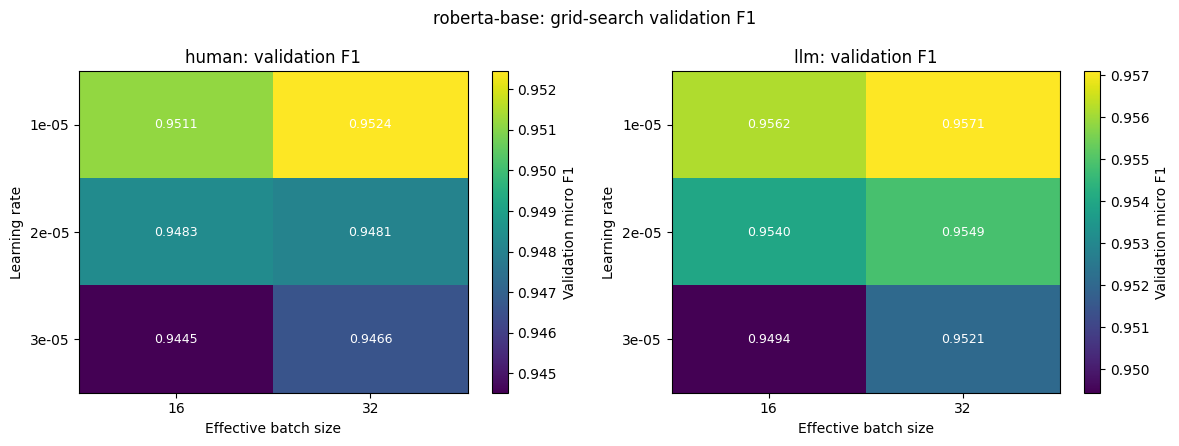

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/grid_heatmap.png


In [33]:
# Grid heatmap: validation F1 per (learning_rate x batch_size), one subplot per side.
_sides_with_grid = sorted(grid_summary_df["side"].unique())
fig, axes = plt.subplots(1, len(_sides_with_grid), figsize=(6 * len(_sides_with_grid), 4.5), squeeze=False)
for ax, side in zip(axes[0], _sides_with_grid):
    pivot = grid_summary_df[grid_summary_df["side"] == side].pivot(
        index="learning_rate", columns="batch_size", values="val_f1"
    )
    im = ax.imshow(pivot.values, cmap=CMAP_SEQUENTIAL, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), pivot.columns)
    ax.set_yticks(range(len(pivot.index)), [f"{lr:.0e}" for lr in pivot.index])
    ax.set_xlabel("Effective batch size")
    ax.set_ylabel("Learning rate")
    ax.set_title(f"{side}: validation F1")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f"{val:.4f}", ha="center", va="center", color="white", fontsize=9)
    fig.colorbar(im, ax=ax, label="Validation micro F1")
fig.suptitle(f"{MODEL}: grid-search validation F1")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "grid_heatmap.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'grid_heatmap.png'}")


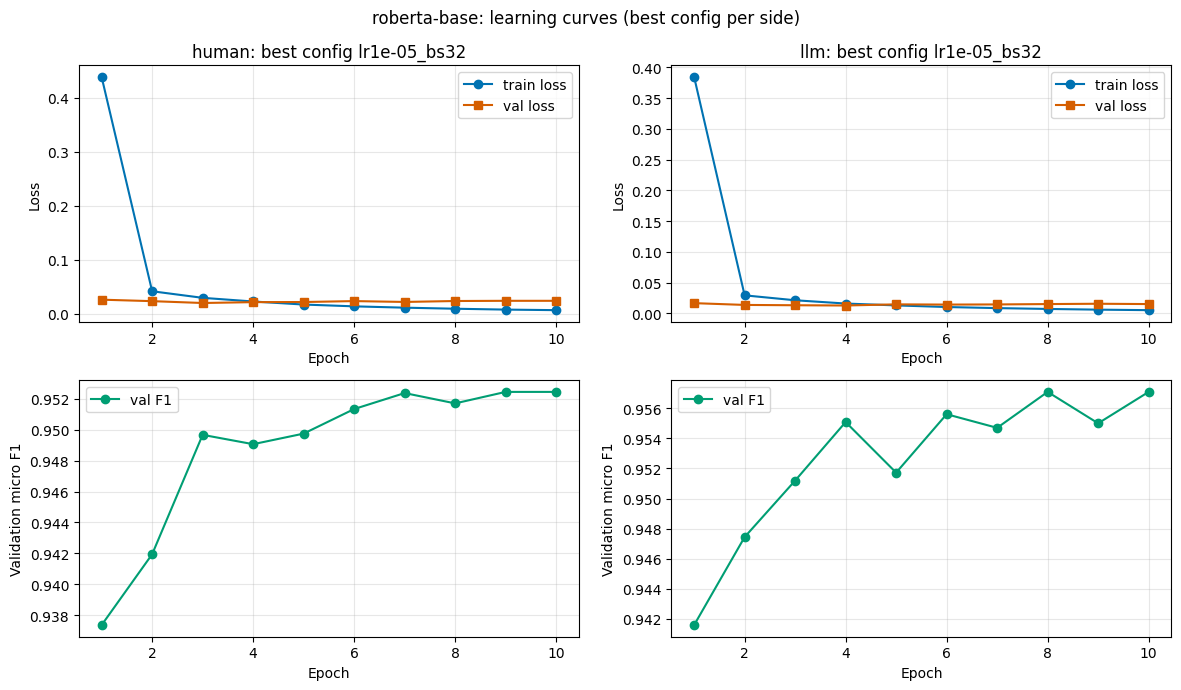

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/learning_curves.png


In [34]:
# Learning curves for each side's best-so-far config (train loss, val loss, val F1 per epoch).
fig, axes = plt.subplots(2, len(_sides_with_grid), figsize=(6 * len(_sides_with_grid), 7), squeeze=False)
for col, side in enumerate(_sides_with_grid):
    best_row = grid_summary_df[grid_summary_df["side"] == side].iloc[0]
    history_csv = CONFIGS_DIR / f"{side}_{best_row['config']}_history.csv"
    history_df = pd.read_csv(history_csv)

    ax_loss = axes[0][col]
    ax_loss.plot(history_df["epoch"], history_df["train_loss"], marker="o", color=PALETTE["blue"], label="train loss")
    ax_loss.plot(history_df["epoch"], history_df["eval_loss"], marker="s", color=PALETTE["vermillion"], label="val loss")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss")
    ax_loss.set_title(f"{side}: best config {best_row['config']}")
    ax_loss.legend()
    ax_loss.grid(alpha=0.3)

    ax_f1 = axes[1][col]
    ax_f1.plot(history_df["epoch"], history_df["eval_f1"], marker="o", color=PALETTE["green"], label="val F1")
    ax_f1.set_xlabel("Epoch")
    ax_f1.set_ylabel("Validation micro F1")
    ax_f1.legend()
    ax_f1.grid(alpha=0.3)

fig.suptitle(f"{MODEL}: learning curves (best config per side)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_curves.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'learning_curves.png'}")


## 11. Reload-and-verify best models


In [35]:
# For each side with a finished best model: reload it fresh from Drive, run the robust chunked-inference
# engine (Section 7) on that side's validation set, and confirm the resulting F1 reproduces the recorded
# grid-search val_f1 within CODE_CHECK_TOLERANCE -- BEFORE any test evaluation is allowed to run. This is
# the project's standard "don't trust a result until it's been reproduced" check (same spirit as notebook
# 03's CoNLL code check). Also writes val_predictions/{side}.jsonl.
val_reload_results = {}
for side in SIDES_TO_RUN:
    best_dir = CKPT_DIR / side / "best"
    best_marker_path = CONFIGS_DIR / f"{side}_best_marker.json"
    if not best_dir.exists() or not best_marker_path.exists():
        print(f"{side}: no finished best model yet -- skipping reload check.")
        continue

    marker = load_json(best_marker_path)
    model = AutoModelForTokenClassification.from_pretrained(best_dir).to(device).eval()

    val_records = silver[(side, "validation")]
    tag_lists, chunked_flags, n_zero = predict_tags_for_sentences(model, [r["tokens"] for r in val_records])
    for tags, rec in zip(tag_lists, val_records):
        assert len(tags) == len(rec["tokens"]), f"{side} validation {rec['sent_id']}: prediction length mismatch"

    gold_lists = [r["ner_tags"] for r in val_records]
    reload_f1 = f1_score(gold_lists, tag_lists)
    diff = abs(reload_f1 - marker["val_f1"])
    assert diff <= CODE_CHECK_TOLERANCE, (
        f"{side}: reload val F1 {reload_f1:.4f} differs from recorded best {marker['val_f1']:.4f} "
        f"by {diff:.4f} > tolerance {CODE_CHECK_TOLERANCE}"
    )

    write_jsonl(
        [
            {"sent_id": r["sent_id"], "article_id": r["article_id"], "predicted_tags": tags}
            for r, tags in zip(val_records, tag_lists)
        ],
        VAL_PREDICTIONS_DIR / f"{side}.jsonl",
    )
    val_reload_results[side] = {
        "recorded_val_f1": marker["val_f1"], "reload_val_f1": reload_f1, "diff": diff,
        "n_chunked": sum(chunked_flags), "n_zero_subword": n_zero,
    }
    logger.info(
        f"{side}: reload check OK (recorded={marker['val_f1']:.4f}, reload={reload_f1:.4f}, diff={diff:.4f}, "
        f"n_chunked={sum(chunked_flags)}, n_zero_subword={n_zero})"
    )
    del model
    gc.collect()
    torch.cuda.empty_cache()

display(pd.DataFrame(val_reload_results).T if val_reload_results else pd.DataFrame())


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

2026-11-09 06:22:30,893 [INFO] human: reload check OK (recorded=0.9524, reload=0.9524, diff=0.0001, n_chunked=0, n_zero_subword=0)
INFO:main_roberta-base_full:human: reload check OK (recorded=0.9524, reload=0.9524, diff=0.0001, n_chunked=0, n_zero_subword=0)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

2026-11-09 06:22:36,911 [INFO] llm: reload check OK (recorded=0.9571, reload=0.9571, diff=0.0000, n_chunked=0, n_zero_subword=0)
INFO:main_roberta-base_full:llm: reload check OK (recorded=0.9571, reload=0.9571, diff=0.0000, n_chunked=0, n_zero_subword=0)


,recorded_val_f1,reload_val_f1,diff,n_chunked,n_zero_subword
human,0.952440,0.952368,0.000072,0.0,0.0
llm,0.957097,0.957097,0.000000,0.0,0.0


## 12. Test evaluation gate


In [36]:
# The 2x2 test evaluation only makes sense once BOTH sides have a finished, verified best model -- which
# may not be true yet if this Colab account only ran SIDES_TO_RUN=["human"] (the other side running on a
# teammate's account/Drive). Print exactly what's missing and stop cleanly rather than erroring.
_missing_sides = [
    side for side in ["human", "llm"]
    if not (CKPT_DIR / side / "best").exists() or side not in val_reload_results
]
if _missing_sides:
    RUN_TEST_EVAL = False
    print(
        f"Test evaluation SKIPPED: missing a finished + verified best model for side(s) {_missing_sides}. "
        f"Run this notebook (or have a teammate run it on another account/Drive) with "
        f"SIDES_TO_RUN={_missing_sides!r}, then re-run this notebook to reach the 2x2 evaluation."
    )
else:
    RUN_TEST_EVAL = True
    print("Both sides have a finished, verified best model. Proceeding to the 2x2 test evaluation.")


Both sides have a finished, verified best model. Proceeding to the 2x2 test evaluation.


## 13. 2x2 test evaluation


In [37]:
# Load each side's best model once, predict on BOTH test sets with the chunked inference engine (Section
# 7), and save per-cell results + predictions. Each cell's {TAG}_{trained}_on_{tested}.json is written once
# and skipped on rerun unless FORCE_REBUILD, matching notebook 02/04's "test touched exactly once" policy.
pred_by_combo = {}       # (trained, tested) -> list of predicted tag lists, aligned with silver[(tested, "test")]
results_2x2_rows, per_type_rows = [], []

if RUN_TEST_EVAL:
    for trained in ["human", "llm"]:
        cell_json_paths = {tested: RESULTS_DIR / f"{TAG}_{trained}_on_{tested}.json" for tested in ["human", "llm"]}
        if all(p.exists() for p in cell_json_paths.values()) and not FORCE_REBUILD:
            for tested, p in cell_json_paths.items():
                cell_result = load_json(p)
                pred_records = load_jsonl(PREDICTIONS_DIR / f"{TAG}_{trained}_on_{tested}.jsonl")
                pred_by_combo[(trained, tested)] = [r["predicted_tags"] for r in pred_records]
                results_2x2_rows.append({
                    "trained_on": trained, "tested_on": tested, "micro_f1": cell_result["f1"],
                    "macro_f1": cell_result["macro_f1"], "precision": cell_result["precision"],
                    "recall": cell_result["recall"],
                })
                for etype, type_metrics in cell_result["report"].items():
                    if etype in ("micro avg", "macro avg", "weighted avg"):
                        continue
                    per_type_rows.append({
                        "trained_on": trained, "tested_on": tested, "entity_type": etype,
                        "f1": type_metrics["f1-score"], "precision": type_metrics["precision"],
                        "recall": type_metrics["recall"], "support": type_metrics["support"],
                    })
            logger.info(f"trained={trained}: both cells already evaluated, loaded from Drive")
            continue

        best_dir = CKPT_DIR / trained / "best"
        model = AutoModelForTokenClassification.from_pretrained(best_dir).to(device).eval()
        for tested in ["human", "llm"]:
            cell_json_path = cell_json_paths[tested]
            pred_jsonl_path = PREDICTIONS_DIR / f"{TAG}_{trained}_on_{tested}.jsonl"
            if cell_json_path.exists() and not FORCE_REBUILD:
                cell_result = load_json(cell_json_path)
                pred_records = load_jsonl(pred_jsonl_path)
                y_pred = [r["predicted_tags"] for r in pred_records]
            else:
                test_records = silver[(tested, "test")]
                y_pred, chunked_flags, n_zero = predict_tags_for_sentences(model, [r["tokens"] for r in test_records])
                for tags, rec in zip(y_pred, test_records):
                    assert len(tags) == len(rec["tokens"]), f"tested={tested} {rec['sent_id']}: prediction length mismatch"
                y_test = [r["ner_tags"] for r in test_records]

                metrics = evaluate(y_test, y_pred)
                cell_result = {
                    "model": MODEL, "trained_on": trained, "tested_on": tested,
                    "precision": metrics["precision"], "recall": metrics["recall"], "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"], "report": metrics["report"],
                    "n_chunked": sum(chunked_flags), "n_zero_subword": n_zero,
                    "evaluated_at": datetime.now(timezone.utc).isoformat(),
                }
                save_json(cell_result, cell_json_path)
                write_jsonl(
                    [
                        {"sent_id": r["sent_id"], "article_id": r["article_id"], "predicted_tags": tags}
                        for r, tags in zip(test_records, y_pred)
                    ],
                    pred_jsonl_path,
                )
                logger.info(
                    f"trained={trained} tested={tested}: micro_f1={metrics['f1']:.4f} macro_f1={metrics['macro_f1']:.4f} "
                    f"n_chunked={sum(chunked_flags)} n_zero_subword={n_zero}"
                )

            pred_by_combo[(trained, tested)] = y_pred
            results_2x2_rows.append({
                "trained_on": trained, "tested_on": tested, "micro_f1": cell_result["f1"],
                "macro_f1": cell_result["macro_f1"], "precision": cell_result["precision"],
                "recall": cell_result["recall"],
            })
            for etype, type_metrics in cell_result["report"].items():
                if etype in ("micro avg", "macro avg", "weighted avg"):
                    continue
                per_type_rows.append({
                    "trained_on": trained, "tested_on": tested, "entity_type": etype,
                    "f1": type_metrics["f1-score"], "precision": type_metrics["precision"],
                    "recall": type_metrics["recall"], "support": type_metrics["support"],
                })

        del model
        gc.collect()
        torch.cuda.empty_cache()

    results_2x2_df = pd.DataFrame(results_2x2_rows)
    results_2x2_df.to_csv(RESULTS_2X2_CSV, index=False)
    per_type_f1_df = pd.DataFrame(per_type_rows)
    per_type_f1_df.to_csv(PER_TYPE_F1_CSV, index=False)
    display(results_2x2_df)
    display(per_type_f1_df)
else:
    results_2x2_df = pd.DataFrame()
    per_type_f1_df = pd.DataFrame()


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

2026-11-09 06:22:47,611 [INFO] trained=human tested=human: micro_f1=0.9408 macro_f1=0.9365 n_chunked=0 n_zero_subword=0
INFO:main_roberta-base_full:trained=human tested=human: micro_f1=0.9408 macro_f1=0.9365 n_chunked=0 n_zero_subword=0
2026-11-09 06:22:54,713 [INFO] trained=human tested=llm: micro_f1=0.9422 macro_f1=0.9399 n_chunked=0 n_zero_subword=0
INFO:main_roberta-base_full:trained=human tested=llm: micro_f1=0.9422 macro_f1=0.9399 n_chunked=0 n_zero_subword=0


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

2026-11-09 06:23:05,322 [INFO] trained=llm tested=human: micro_f1=0.9355 macro_f1=0.9303 n_chunked=0 n_zero_subword=0
INFO:main_roberta-base_full:trained=llm tested=human: micro_f1=0.9355 macro_f1=0.9303 n_chunked=0 n_zero_subword=0
2026-11-09 06:23:12,361 [INFO] trained=llm tested=llm: micro_f1=0.9469 macro_f1=0.9452 n_chunked=0 n_zero_subword=0
INFO:main_roberta-base_full:trained=llm tested=llm: micro_f1=0.9469 macro_f1=0.9452 n_chunked=0 n_zero_subword=0


,trained_on,tested_on,micro_f1,macro_f1,precision,recall
0,human,human,0.940845,0.936518,0.940069,0.941622
1,human,llm,0.942219,0.939875,0.944030,0.940415
2,llm,human,0.935457,0.930280,0.933023,0.937904
3,llm,llm,0.946942,0.945217,0.945030,0.948862


,trained_on,tested_on,entity_type,f1,precision,recall,support
0,human,human,LOC,0.965052,0.957440,0.972785,3307
1,human,human,MISC,0.896654,0.893863,0.899463,3352
2,human,human,ORG,0.912411,0.922393,0.902643,2989
3,human,human,PER,0.971955,0.970564,0.973350,4878
4,human,llm,LOC,0.967682,0.963235,0.972171,2156
5,human,llm,MISC,0.898294,0.900433,0.896165,2321
6,human,llm,ORG,0.919156,0.928402,0.910093,1724
7,human,llm,PER,0.974369,0.976012,0.972731,2677
8,llm,human,LOC,0.964356,0.959306,0.969459,3307
9,llm,human,MISC,0.883229,0.881916,0.884547,3352


## 14. Paired bootstrap


In [38]:
# Precompute per-article (tp, fp, fn) for all 4 (trained, tested) combinations, then verify the summed
# counts reproduce seqeval's micro F1 EXACTLY before trusting the bootstrap -- same two-step pattern as
# notebook 04 Sections 10's first two cells.
if RUN_TEST_EVAL:
    counts_by_combo = {
        (trained, tested): article_counts(silver[(tested, "test")], pred_by_combo[(trained, tested)])
        for trained in ["human", "llm"] for tested in ["human", "llm"]
    }

    for (trained, tested), by_article in counts_by_combo.items():
        tp = sum(c[0] for c in by_article.values())
        fp = sum(c[1] for c in by_article.values())
        fn = sum(c[2] for c in by_article.values())
        our_f1 = _micro_f1_from_counts(tp, fp, fn)
        seqeval_f1 = f1_score(
            [r["ner_tags"] for r in silver[(tested, "test")]], pred_by_combo[(trained, tested)]
        )
        assert abs(our_f1 - seqeval_f1) < 1e-6, (
            f"trained={trained} tested={tested}: article_counts F1 ({our_f1:.6f}) != seqeval F1 ({seqeval_f1:.6f})"
        )
    logger.info("Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 4 combinations")
    print("Verified: article_counts-derived F1 matches seqeval's F1 exactly (diff < 1e-6) for all 4 cells.")


2026-11-09 06:23:14,550 [INFO] Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 4 combinations
INFO:main_roberta-base_full:Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 4 combinations


Verified: article_counts-derived F1 matches seqeval's F1 exactly (diff < 1e-6) for all 4 cells.


In [39]:
# The same four comparisons as notebook 04's protocol, computed with the identical paired_bootstrap code.
if RUN_TEST_EVAL:
    comparisons = {
        "human_test: human_trained - llm_trained": (("human", "human"), ("llm", "human")),
        "llm_test: human_trained - llm_trained": (("human", "llm"), ("llm", "llm")),
        "human_trained: human_test - llm_test": (("human", "human"), ("human", "llm")),
        "llm_trained: human_test - llm_test": (("llm", "human"), ("llm", "llm")),
    }
    active_n_bootstrap = 100 if SMOKE_TEST else N_BOOTSTRAP
    bootstrap_ci_df = paired_bootstrap(counts_by_combo, comparisons, active_n_bootstrap, SEED)
    bootstrap_ci_df.to_csv(BOOTSTRAP_CI_CSV, index=False)

    _display_df = bootstrap_ci_df.copy()
    _display_df["reliable"] = _display_df["reliable"].map({True: "reliable (CI excludes 0)", False: "not reliable"})
    display(_display_df)
else:
    bootstrap_ci_df = pd.DataFrame()


,comparison,observed_difference,ci_low,ci_high,reliable
0,human_test: human_trained - llm_trained,0.005387,0.001900,0.008777,reliable (CI excludes 0)
1,llm_test: human_trained - llm_trained,-0.004724,-0.008864,-0.000645,reliable (CI excludes 0)
2,human_trained: human_test - llm_test,-0.001374,-0.008999,0.006070,not reliable
3,llm_trained: human_test - llm_test,-0.011485,-0.019969,-0.002641,reliable (CI excludes 0)


## 15. Per-topic and per-type origin gaps

"Origin gap" = F1(human test) - F1(llm test), holding the trained model fixed -- the same comparison as
bootstrap rows 2/4 above, broken down by entity type and by topic. These are **descriptive point
estimates**, not individually significance-tested (per-cell samples are too small for a separate bootstrap
CI per type/topic) -- the same caveat notebook 04 Section 14 states for the CRF baseline.


In [40]:
# Per-topic F1: join each (trained, tested) combo's predictions onto the original test file (which has
# `topic`) via sent_id, and accumulate span-level (tp, fp, fn) per topic. Same logic as notebook 04 Section
# 14, reusing in-memory predictions instead of reloading from Drive (we are in the same run).
if RUN_TEST_EVAL:
    topic_counts = defaultdict(lambda: [0, 0, 0])  # (trained, tested, topic) -> [tp, fp, fn]
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            test_records = silver[(tested, "test")]
            for rec, pred_tags in zip(test_records, pred_by_combo[(trained, tested)]):
                gold_spans = set(extract_spans(rec["ner_tags"]))
                pred_spans = set(extract_spans(pred_tags))
                key = (trained, tested, rec["topic"])
                topic_counts[key][0] += len(gold_spans & pred_spans)
                topic_counts[key][1] += len(pred_spans - gold_spans)
                topic_counts[key][2] += len(gold_spans - pred_spans)

    per_topic_f1_df = pd.DataFrame([
        {"trained_on": trained, "tested_on": tested, "topic": topic,
         "f1": _micro_f1_from_counts(*counts), "n_entities_gold": counts[0] + counts[2]}
        for (trained, tested, topic), counts in topic_counts.items()
    ])
    per_topic_f1_df.to_csv(PER_TOPIC_F1_CSV, index=False)
    display(per_topic_f1_df.sort_values(["trained_on", "topic", "tested_on"]))
else:
    per_topic_f1_df = pd.DataFrame()


,trained_on,tested_on,topic,f1,n_entities_gold
3,human,human,Celebrity,0.903074,2961
9,human,llm,Celebrity,0.920329,1765
0,human,human,History and religion,0.942563,3405
6,human,llm,History and religion,0.939690,2104
4,human,human,Politics and government,0.977222,1997
10,human,llm,Politics and government,0.969867,1247
1,human,human,Science and technology,0.957176,1726
7,human,llm,Science and technology,0.954631,1059
2,human,human,Social culture and civil rights,0.944204,2301
8,human,llm,Social culture and civil rights,0.944073,1427


In [41]:
# Topics ranked by |F1(human test) - F1(llm test)|, per trained model.
if RUN_TEST_EVAL:
    topic_pivot = per_topic_f1_df.pivot_table(index=["trained_on", "topic"], columns="tested_on", values="f1").reset_index()
    topic_pivot["origin_gap"] = topic_pivot["human"] - topic_pivot["llm"]
    topic_pivot["abs_gap"] = topic_pivot["origin_gap"].abs()
    topic_pivot = topic_pivot.sort_values(["trained_on", "abs_gap"], ascending=[True, False])
    topic_pivot.to_csv(PER_TOPIC_ORIGIN_GAP_CSV, index=False)
    print("Topics ranked by |F1(human test) - F1(llm test)|, per trained model (descriptive point estimates):")
    display(topic_pivot[["trained_on", "topic", "human", "llm", "origin_gap"]])


Topics ranked by |F1(human test) - F1(llm test)|, per trained model (descriptive point estimates):


tested_on,trained_on,topic,human,llm,origin_gap
0,human,Celebrity,0.903074,0.920329,-0.017255
2,human,Politics and government,0.977222,0.969867,0.007354
1,human,History and religion,0.942563,0.939690,0.002872
5,human,Sports,0.939878,0.937304,0.002574
3,human,Science and technology,0.957176,0.954631,0.002545
4,human,Social culture and civil rights,0.944204,0.944073,0.000131
6,llm,Celebrity,0.897108,0.926334,-0.029225
11,llm,Sports,0.933333,0.946547,-0.013214
10,llm,Social culture and civil rights,0.946344,0.956674,-0.010330
8,llm,Politics and government,0.969454,0.974668,-0.005214


In [42]:
# Entity types ranked by |F1(human test) - F1(llm test)|, per trained model -- reuses per_type_f1_df from
# Section 13, no recomputation needed.
if RUN_TEST_EVAL:
    type_pivot = per_type_f1_df.pivot_table(index=["trained_on", "entity_type"], columns="tested_on", values="f1").reset_index()
    type_pivot["origin_gap"] = type_pivot["human"] - type_pivot["llm"]
    type_pivot["abs_gap"] = type_pivot["origin_gap"].abs()
    type_pivot = type_pivot.sort_values(["trained_on", "abs_gap"], ascending=[True, False])
    type_pivot.to_csv(PER_TYPE_ORIGIN_GAP_CSV, index=False)
    print("Entity types ranked by |F1(human test) - F1(llm test)|, per trained model (descriptive point estimates):")
    display(type_pivot[["trained_on", "entity_type", "human", "llm", "origin_gap"]])


Entity types ranked by |F1(human test) - F1(llm test)|, per trained model (descriptive point estimates):


tested_on,trained_on,entity_type,human,llm,origin_gap
2,human,ORG,0.912411,0.919156,-0.006745
0,human,LOC,0.965052,0.967682,-0.002631
3,human,PER,0.971955,0.974369,-0.002414
1,human,MISC,0.896654,0.898294,-0.001640
6,llm,ORG,0.900518,0.928343,-0.027825
5,llm,MISC,0.883229,0.902549,-0.019320
4,llm,LOC,0.964356,0.974965,-0.010610
7,llm,PER,0.973017,0.975009,-0.001992


## 16. Confusion matrices

Two confusion matrices are built for each of the 4 (trained, tested) cells:

**(a) Token-level, 9x9.** A plain confusion matrix over the 9 IOB2 tag strings (`O`, `B-PER`, ..., `I-MISC`),
comparing each token's gold tag to its predicted tag one-for-one -- valid because `predict_tags_for_sentences`
(Section 7) guarantees the predicted tag list is exactly as long as the gold token list for every sentence.

**(b) Entity-level.** Built from `extract_spans` (Section 8) span-matching between gold and predicted spans
in each sentence, independent of the raw token confusion above. Every **gold span** is classified as exactly
one of:
- **correct** -- a predicted span with the identical boundaries AND the identical type.
- **wrong_type** -- a predicted span with the identical boundaries but a DIFFERENT type.
- **partial** (boundary error) -- no identical-boundary predicted span exists, but some predicted span
  overlaps it (any shared token position), regardless of type.
- **missed** -- no predicted span overlaps it at all.

Every **predicted span left unmatched** after all gold spans have claimed their best match (exact match
preferred over overlap; each predicted span can satisfy at most one gold span) is **spurious** -- it has no
overlap with any gold span. Row-normalized tables divide each entity type's row (its 4 gold-outcome counts
plus its own spurious count) by that row's total, so "spurious" is reported per predicted type even though
it has no gold label of its own.


In [43]:
# (a) Token-level 9x9 confusion matrix, raw counts and row-normalized, for all 4 cells.
def token_confusion_matrix(gold_tag_lists, pred_tag_lists):
    y_true = [t for seq in gold_tag_lists for t in seq]
    y_pred = [t for seq in pred_tag_lists for t in seq]
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_NAMES)
    return pd.DataFrame(cm, index=LABEL_NAMES, columns=LABEL_NAMES)


def row_normalize(df):
    row_sums = df.sum(axis=1).replace(0, np.nan)
    return df.div(row_sums, axis=0).fillna(0.0)


token_cms = {}
if RUN_TEST_EVAL:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            gold_lists = [r["ner_tags"] for r in silver[(tested, "test")]]
            pred_lists = pred_by_combo[(trained, tested)]
            cm_df = token_confusion_matrix(gold_lists, pred_lists)
            cm_norm_df = row_normalize(cm_df)
            token_cms[(trained, tested)] = (cm_df, cm_norm_df)
            cm_df.to_csv(CONFUSION_DIR / f"token_{trained}_on_{tested}_raw.csv")
            cm_norm_df.to_csv(CONFUSION_DIR / f"token_{trained}_on_{tested}_norm.csv")
    print(f"Saved {len(token_cms) * 2} token-level confusion-matrix CSVs to {CONFUSION_DIR}")


Saved 8 token-level confusion-matrix CSVs to /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/confusion_matrices


In [44]:
# (b) Entity-level span classification: correct / wrong_type / partial / missed (per gold span), plus
# spurious (per leftover, non-overlapping predicted span).
def classify_entity_spans(gold_tags, pred_tags):
    gold_spans = extract_spans(gold_tags)
    pred_spans = extract_spans(pred_tags)
    pred_used = [False] * len(pred_spans)
    results = []  # (row_type, category) -- row_type is the gold type, or the predicted type for "spurious"
    for g_type, g_s, g_e in gold_spans:
        exact_idx = next(
            (i for i, (p_type, p_s, p_e) in enumerate(pred_spans) if p_s == g_s and p_e == g_e and not pred_used[i]),
            None,
        )
        if exact_idx is not None:
            pred_used[exact_idx] = True
            p_type = pred_spans[exact_idx][0]
            results.append((g_type, "correct" if p_type == g_type else "wrong_type"))
            continue
        overlap_idx = next(
            (i for i, (p_type, p_s, p_e) in enumerate(pred_spans) if not pred_used[i] and p_s < g_e and p_e > g_s),
            None,
        )
        if overlap_idx is not None:
            pred_used[overlap_idx] = True
            results.append((g_type, "partial"))
            continue
        results.append((g_type, "missed"))
    for i, (p_type, p_s, p_e) in enumerate(pred_spans):
        if not pred_used[i]:
            results.append((p_type, "spurious"))
    return results


ENTITY_CM_CATEGORIES = ["correct", "wrong_type", "partial", "missed", "spurious"]

entity_cms = {}
if RUN_TEST_EVAL:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            counts = pd.DataFrame(0, index=ENTITY_TYPES, columns=ENTITY_CM_CATEGORIES)
            for rec, pred_tags in zip(silver[(tested, "test")], pred_by_combo[(trained, tested)]):
                for row_type, category in classify_entity_spans(rec["ner_tags"], pred_tags):
                    counts.loc[row_type, category] += 1
            counts_norm = row_normalize(counts)
            entity_cms[(trained, tested)] = (counts, counts_norm)
            counts.to_csv(CONFUSION_DIR / f"entity_{trained}_on_{tested}_raw.csv")
            counts_norm.to_csv(CONFUSION_DIR / f"entity_{trained}_on_{tested}_norm.csv")
    print(f"Saved {len(entity_cms) * 2} entity-level confusion-matrix CSVs to {CONFUSION_DIR}")


Saved 8 entity-level confusion-matrix CSVs to /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/confusion_matrices


In [45]:
# Hand-computed unit test for classify_entity_spans, covering all 5 categories on one synthetic sentence.
_g = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "I-LOC", "O", "B-MISC"]
#      PER span (0,2) exact match below -> correct
#      ORG span (3,4) predicted as LOC -> wrong_type
#      LOC span (5,7) predicted as (5,6) only -> partial (overlap, wrong boundary)
#      MISC span (8,9) has no predicted overlap -> missed
_p = ["B-PER", "I-PER", "O", "B-LOC", "O", "B-LOC", "O", "B-ORG", "O"]
#      extra ORG span at (7,8) has no gold overlap -> spurious
_result = classify_entity_spans(_g, _p)
_expected = [("PER", "correct"), ("ORG", "wrong_type"), ("LOC", "partial"), ("MISC", "missed"), ("ORG", "spurious")]
assert _result == _expected, f"classify_entity_spans mismatch: got {_result}, expected {_expected}"
print("classify_entity_spans unit test passed: correct, wrong_type, partial, missed, spurious all verified.")


classify_entity_spans unit test passed: correct, wrong_type, partial, missed, spurious all verified.


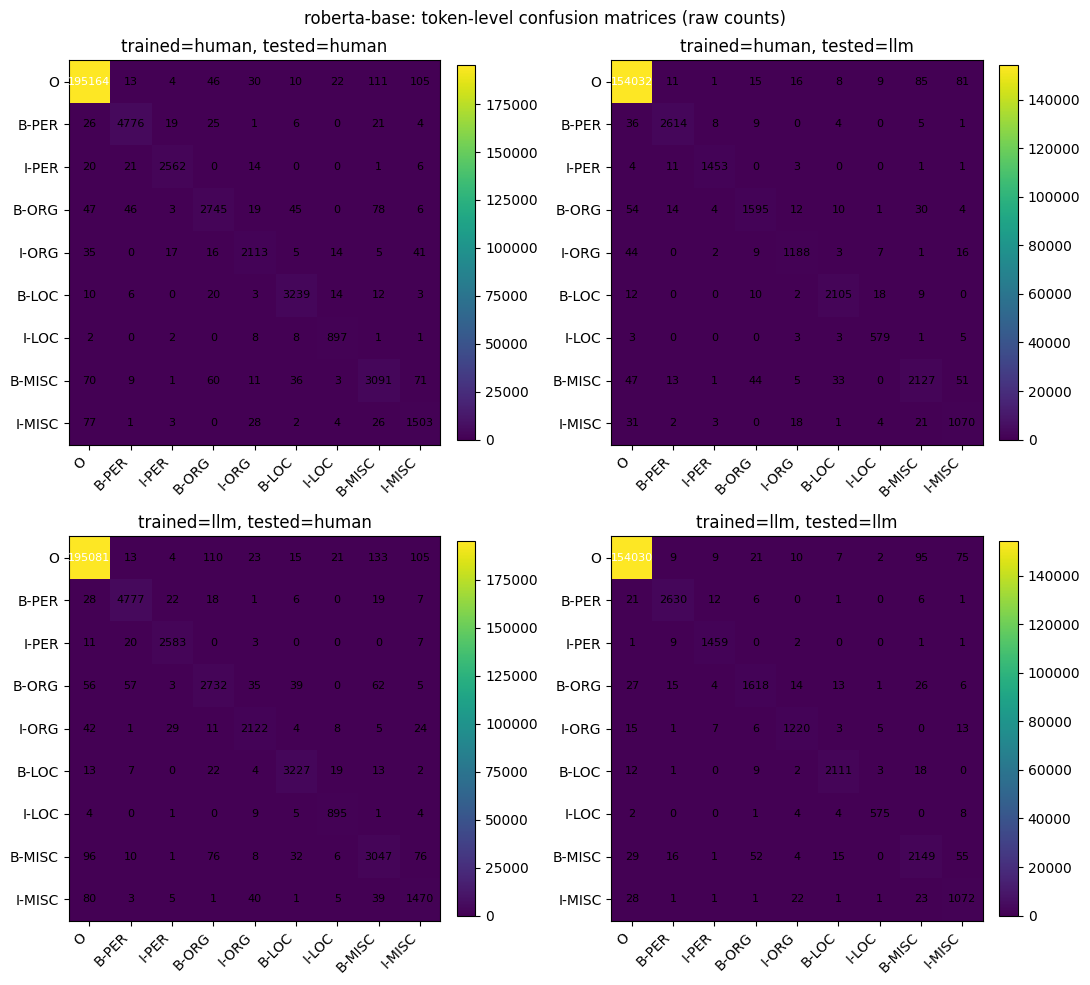

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/confusion_token_raw.png


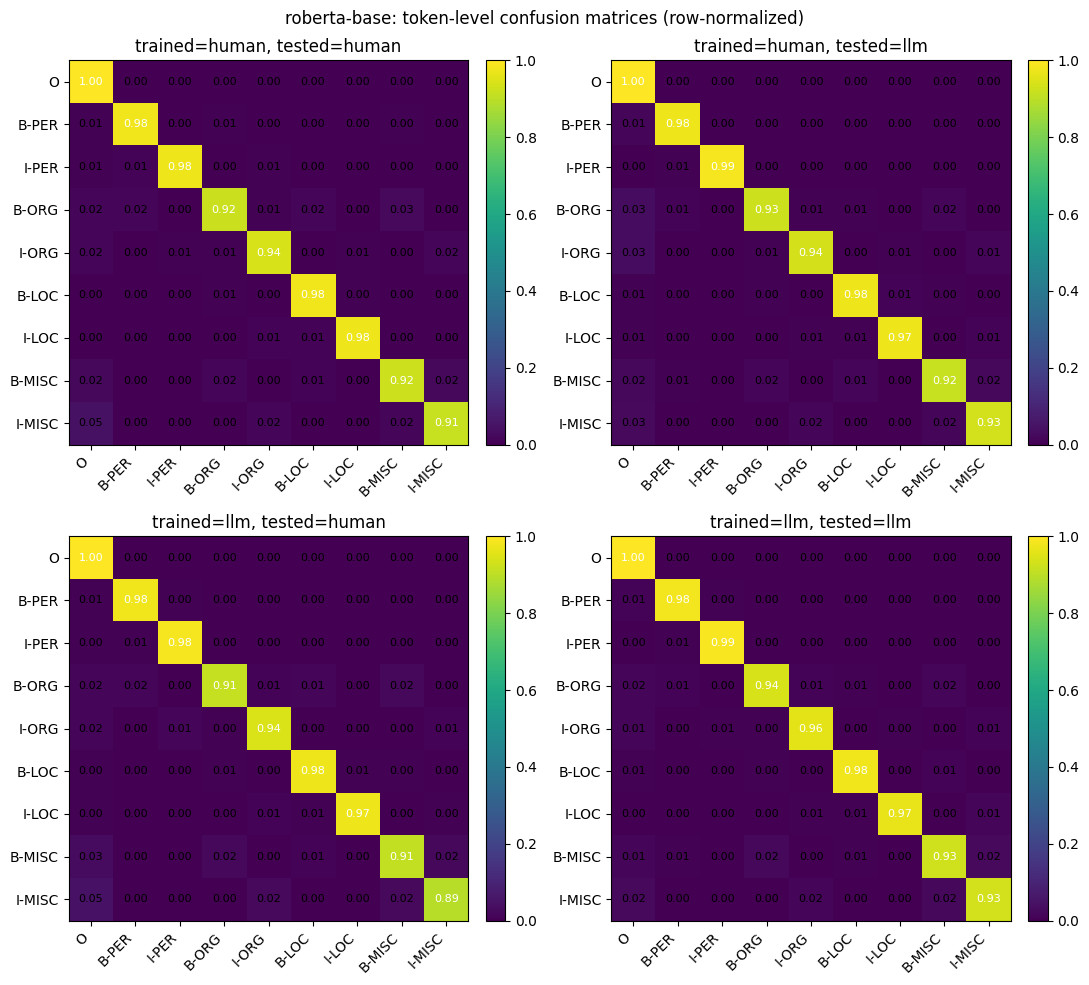

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/confusion_token_norm.png


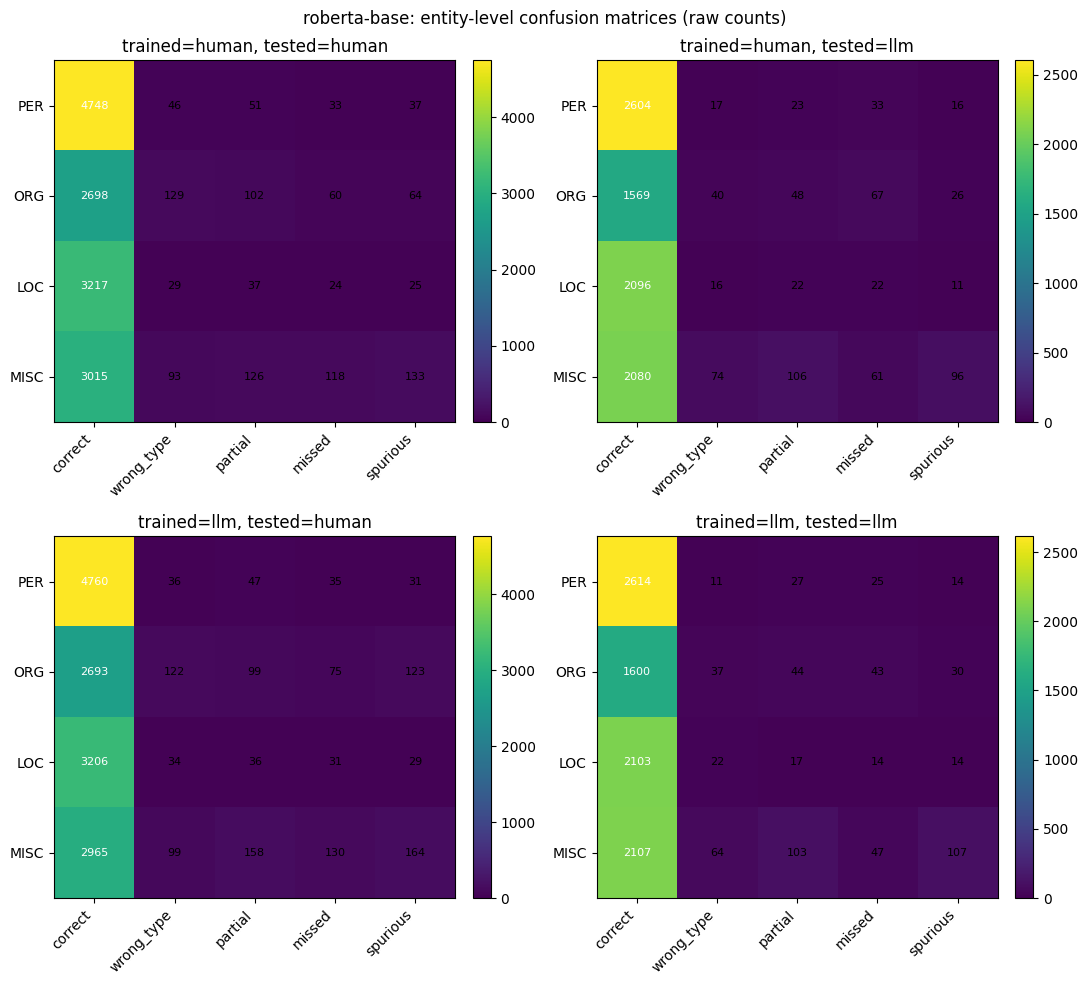

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/confusion_entity_raw.png


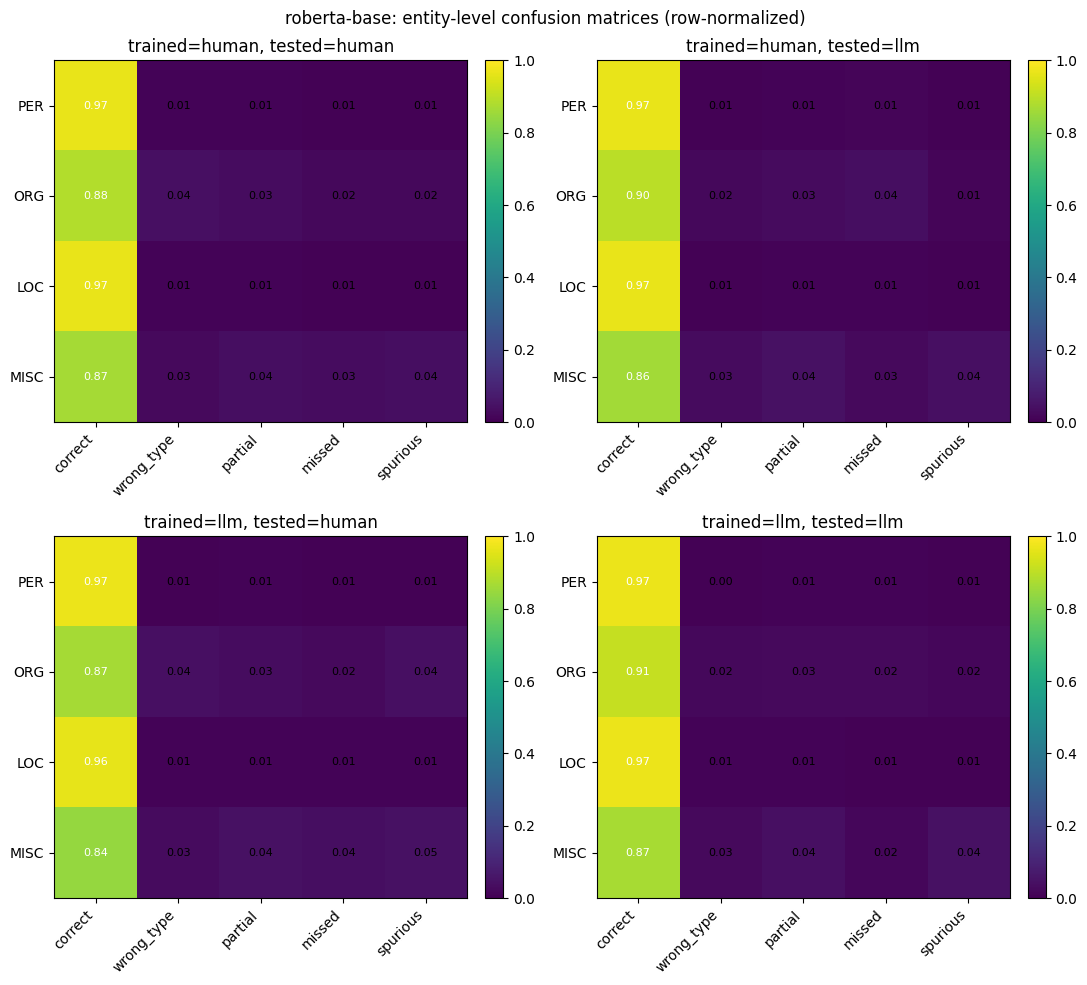

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/confusion_entity_norm.png


In [46]:
# Confusion-matrix figures: one combined figure per (type, raw/normalized) -- 4 PNGs total, each with one
# subplot per (trained, tested) cell, so file count stays manageable while every cell is still shown.
def plot_confusion_grid(cms_by_combo, labels, title, out_path, normalized):
    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    combos = [("human", "human"), ("human", "llm"), ("llm", "human"), ("llm", "llm")]
    for ax, (trained, tested) in zip(axes.flat, combos):
        df = cms_by_combo[(trained, tested)][1 if normalized else 0]
        im = ax.imshow(df.values, cmap=CMAP_SEQUENTIAL, vmin=0, vmax=1 if normalized else None, aspect="auto")
        ax.set_xticks(range(len(df.columns)), df.columns, rotation=45, ha="right")
        ax.set_yticks(range(len(df.index)), df.index)
        ax.set_title(f"trained={trained}, tested={tested}")
        fmt = "{:.2f}" if normalized else "{:.0f}"
        for i in range(df.shape[0]):
            for j in range(df.shape[1]):
                ax.text(j, i, fmt.format(df.values[i, j]), ha="center", va="center",
                         color="white" if (not normalized and df.values[i, j] > df.values.max() / 2) or (normalized and df.values[i, j] > 0.5) else "black",
                         fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved {out_path}")


if RUN_TEST_EVAL:
    plot_confusion_grid(token_cms, LABEL_NAMES, f"{MODEL}: token-level confusion matrices (raw counts)",
                         FIGURES_DIR / "confusion_token_raw.png", normalized=False)
    plot_confusion_grid(token_cms, LABEL_NAMES, f"{MODEL}: token-level confusion matrices (row-normalized)",
                         FIGURES_DIR / "confusion_token_norm.png", normalized=True)
    plot_confusion_grid(entity_cms, ENTITY_CM_CATEGORIES, f"{MODEL}: entity-level confusion matrices (raw counts)",
                         FIGURES_DIR / "confusion_entity_raw.png", normalized=False)
    plot_confusion_grid(entity_cms, ENTITY_CM_CATEGORIES, f"{MODEL}: entity-level confusion matrices (row-normalized)",
                         FIGURES_DIR / "confusion_entity_norm.png", normalized=True)


## 17. Additional figures


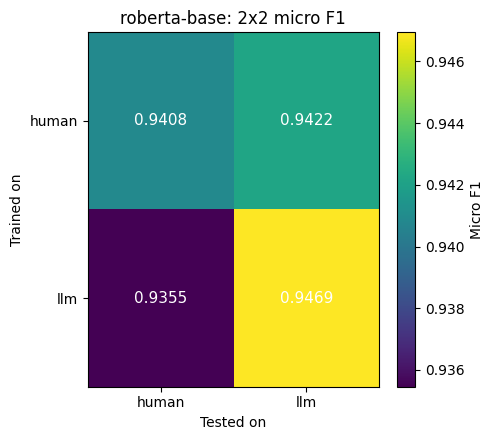

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/f1_2x2_heatmap.png


In [47]:
# 2x2 micro F1 heatmap (trained_on x tested_on).
if RUN_TEST_EVAL:
    pivot = results_2x2_df.pivot(index="trained_on", columns="tested_on", values="micro_f1")
    fig, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(pivot.values, cmap=CMAP_SEQUENTIAL, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), pivot.columns)
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    ax.set_xlabel("Tested on")
    ax.set_ylabel("Trained on")
    ax.set_title(f"{MODEL}: 2x2 micro F1")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, f"{pivot.values[i, j]:.4f}", ha="center", va="center", color="white", fontsize=11)
    fig.colorbar(im, ax=ax, label="Micro F1")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "f1_2x2_heatmap.png", dpi=300)
    plt.show()
    print(f"Saved {FIGURES_DIR / 'f1_2x2_heatmap.png'}")


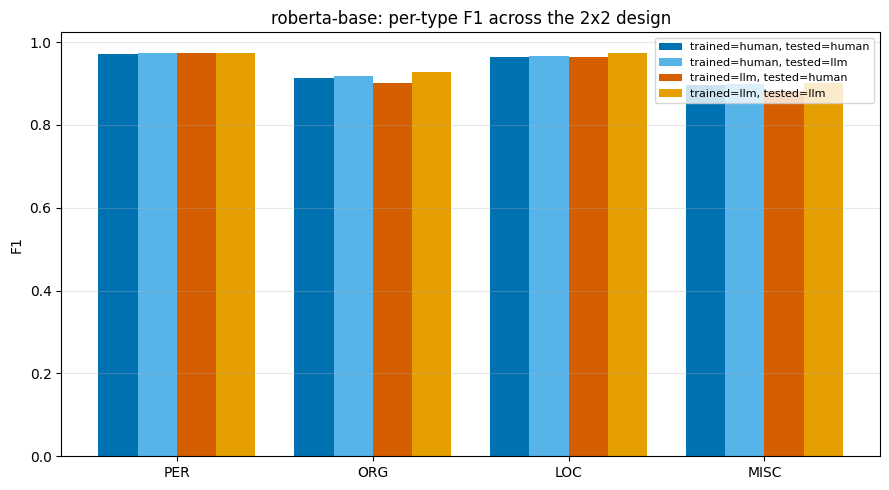

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/per_type_f1.png


In [48]:
# Per-type F1 grouped bar chart: one group per entity type, one bar per (trained, tested) cell.
if RUN_TEST_EVAL:
    _cell_colors = {
        ("human", "human"): PALETTE["blue"], ("human", "llm"): PALETTE["sky"],
        ("llm", "human"): PALETTE["vermillion"], ("llm", "llm"): PALETTE["orange"],
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(ENTITY_TYPES))
    width = 0.2
    for i, (trained, tested) in enumerate([("human", "human"), ("human", "llm"), ("llm", "human"), ("llm", "llm")]):
        sub = per_type_f1_df[(per_type_f1_df["trained_on"] == trained) & (per_type_f1_df["tested_on"] == tested)]
        sub = sub.set_index("entity_type").reindex(ENTITY_TYPES)
        ax.bar(x + (i - 1.5) * width, sub["f1"].values, width,
               label=f"trained={trained}, tested={tested}", color=_cell_colors[(trained, tested)])
    ax.set_xticks(x, ENTITY_TYPES)
    ax.set_ylabel("F1")
    ax.set_title(f"{MODEL}: per-type F1 across the 2x2 design")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "per_type_f1.png", dpi=300)
    plt.show()
    print(f"Saved {FIGURES_DIR / 'per_type_f1.png'}")


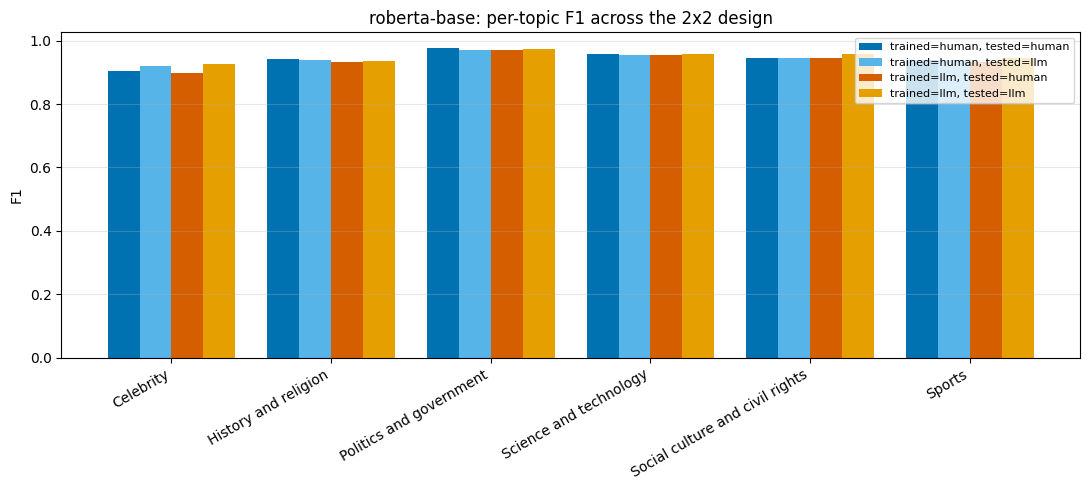

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/per_topic_f1.png


In [49]:
# Per-topic F1 grouped bar chart: one group per topic, one bar per (trained, tested) cell.
if RUN_TEST_EVAL:
    topics = sorted(per_topic_f1_df["topic"].unique())
    fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(len(topics))
    width = 0.2
    for i, (trained, tested) in enumerate([("human", "human"), ("human", "llm"), ("llm", "human"), ("llm", "llm")]):
        sub = per_topic_f1_df[(per_topic_f1_df["trained_on"] == trained) & (per_topic_f1_df["tested_on"] == tested)]
        sub = sub.set_index("topic").reindex(topics)
        ax.bar(x + (i - 1.5) * width, sub["f1"].values, width,
               label=f"trained={trained}, tested={tested}", color=_cell_colors[(trained, tested)])
    ax.set_xticks(x, topics, rotation=30, ha="right")
    ax.set_ylabel("F1")
    ax.set_title(f"{MODEL}: per-topic F1 across the 2x2 design")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "per_topic_f1.png", dpi=300)
    plt.show()
    print(f"Saved {FIGURES_DIR / 'per_topic_f1.png'}")


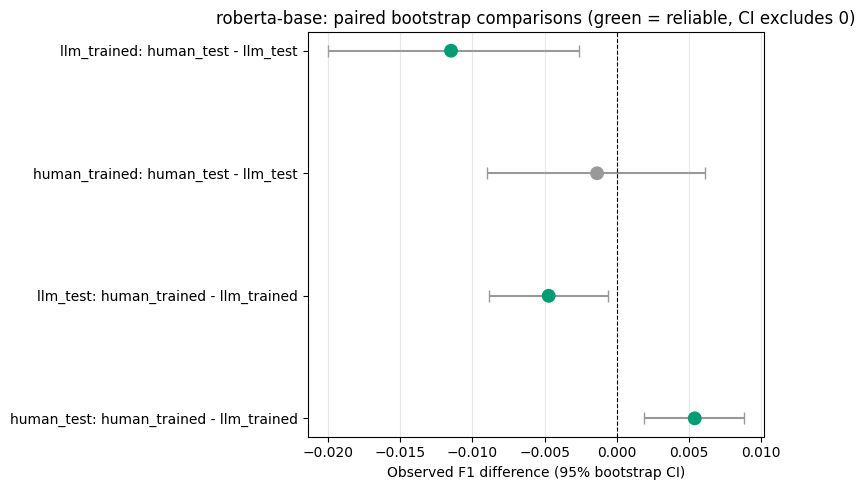

Saved /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/bootstrap_ci.png


In [50]:
# Bootstrap differences with 95% CI error bars, colored by whether the interval excludes zero.
if RUN_TEST_EVAL:
    fig, ax = plt.subplots(figsize=(8, 5))
    y_pos = np.arange(len(bootstrap_ci_df))
    colors = [PALETTE["green"] if r else PALETTE["grey"] for r in bootstrap_ci_df["reliable"]]
    lower_err = bootstrap_ci_df["observed_difference"] - bootstrap_ci_df["ci_low"]
    upper_err = bootstrap_ci_df["ci_high"] - bootstrap_ci_df["observed_difference"]
    ax.errorbar(
        bootstrap_ci_df["observed_difference"], y_pos, xerr=[lower_err, upper_err],
        fmt="o", capsize=4, color=PALETTE["grey"], ecolor=PALETTE["grey"], zorder=1,
    )
    ax.scatter(bootstrap_ci_df["observed_difference"], y_pos, c=colors, s=80, zorder=2)
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_yticks(y_pos, bootstrap_ci_df["comparison"])
    ax.set_xlabel("Observed F1 difference (95% bootstrap CI)")
    ax.set_title(f"{MODEL}: paired bootstrap comparisons (green = reliable, CI excludes 0)")
    ax.grid(alpha=0.3, axis="x")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "bootstrap_ci.png", dpi=300)
    plt.show()
    print(f"Saved {FIGURES_DIR / 'bootstrap_ci.png'}")


## 18. Summary


In [51]:
# Best config per side, the 2x2 micro F1 table, the bootstrap differences, and a present/missing checklist
# of every expected output file.
print("Best config per side:")
for side, b in best_configs.items():
    print(f"  {side}: {b['config']} (lr={b['learning_rate']}, bs={b['batch_size']}), val_f1={b['val_f1']:.4f}")

if RUN_TEST_EVAL:
    print("\n2x2 micro F1 (rows=trained_on, cols=tested_on):")
    display(results_2x2_df.pivot(index="trained_on", columns="tested_on", values="micro_f1"))
    print("\nPaired bootstrap differences (95% CI over test articles):")
    display(bootstrap_ci_df)
else:
    print("\n2x2 evaluation not yet run (see Section 12 for what's missing).")

_expected_files = [
    GRID_SUMMARY_CSV, BEST_CONFIGS_JSON, ENVIRONMENT_JSON, RUN_LOG_TXT,
    FIGURES_DIR / "grid_heatmap.png", FIGURES_DIR / "learning_curves.png",
]
for side in ["human", "llm"]:
    _expected_files.append(VAL_PREDICTIONS_DIR / f"{side}.jsonl")
    _expected_files.append(CKPT_DIR / side / "best" / "config.json")
for trained in ["human", "llm"]:
    for tested in ["human", "llm"]:
        _expected_files.append(RESULTS_DIR / f"{TAG}_{trained}_on_{tested}.json")
        _expected_files.append(PREDICTIONS_DIR / f"{TAG}_{trained}_on_{tested}.jsonl")
        for kind in ["token", "entity"]:
            for suffix in ["raw", "norm"]:
                _expected_files.append(CONFUSION_DIR / f"{kind}_{trained}_on_{tested}_{suffix}.csv")
_expected_files += [
    RESULTS_2X2_CSV, PER_TYPE_F1_CSV, BOOTSTRAP_CI_CSV,
    PER_TOPIC_F1_CSV, PER_TOPIC_ORIGIN_GAP_CSV, PER_TYPE_ORIGIN_GAP_CSV,
    FIGURES_DIR / "f1_2x2_heatmap.png", FIGURES_DIR / "per_type_f1.png", FIGURES_DIR / "per_topic_f1.png",
    FIGURES_DIR / "bootstrap_ci.png",
    FIGURES_DIR / "confusion_token_raw.png", FIGURES_DIR / "confusion_token_norm.png",
    FIGURES_DIR / "confusion_entity_raw.png", FIGURES_DIR / "confusion_entity_norm.png",
]

print("\nOutput file checklist:")
for p in _expected_files:
    status = "OK" if p.exists() else "MISSING"
    print(f"  [{status:7s}] {p}")

if SMOKE_TEST:
    print("\nSmoke test passed. Set SMOKE_TEST = False and run all cells.")


Best config per side:
  human: lr1e-05_bs32 (lr=1e-05, bs=32), val_f1=0.9524
  llm: lr1e-05_bs32 (lr=1e-05, bs=32), val_f1=0.9571

2x2 micro F1 (rows=trained_on, cols=tested_on):


tested_on,human,llm
trained_on,,
human,0.940845,0.942219
llm,0.935457,0.946942



Paired bootstrap differences (95% CI over test articles):


,comparison,observed_difference,ci_low,ci_high,reliable
0,human_test: human_trained - llm_trained,0.005387,0.001900,0.008777,True
1,llm_test: human_trained - llm_trained,-0.004724,-0.008864,-0.000645,True
2,human_trained: human_test - llm_test,-0.001374,-0.008999,0.006070,False
3,llm_trained: human_test - llm_test,-0.011485,-0.019969,-0.002641,True



Output file checklist:
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/grid_summary.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/best_configs.json
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/environment.json
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/run_log.txt
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/grid_heatmap.png
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/figures/learning_curves.png
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/val_predictions/human.jsonl
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/checkpoints/main/roberta-base/human/best/config.json
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/main/roberta-base/val_predictions/llm.jsonl
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/checkpoints/ma

## 19. References

[1] J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of deep bidirectional
transformers for language understanding," in Proc. NAACL-HLT, 2019, pp. 4171-4186.
doi:10.18653/v1/N19-1423

[2] Y. Liu et al., "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[3] E. F. Tjong Kim Sang and F. De Meulder, "Introduction to the CoNLL-2003 shared task:
Language-independent named entity recognition," in Proc. CoNLL, 2003, pp. 142-147. arXiv:cs/0306050

[4] Z. Wang, J. Shang, L. Liu, L. Lu, J. Liu, and J. Han, "CrossWeigh: Training named entity tagger
from imperfect annotations," in Proc. EMNLP-IJCNLP, 2019. https://aclanthology.org/D19-1519/

[5] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in Proc. ICLR, 2019.
arXiv:1711.05101

[6] P. Micikevicius et al., "Mixed precision training," in Proc. ICLR, 2018. arXiv:1710.03740

[7] T. Wolf et al., "Transformers: State-of-the-art natural language processing," in Proc. EMNLP:
System Demonstrations, 2020, pp. 38-45. doi:10.18653/v1/2020.emnlp-demos.6

[8] Q. Lhoest et al., "Datasets: A community library for natural language processing," in Proc.
EMNLP: System Demonstrations, 2021. doi:10.18653/v1/2021.emnlp-demo.21

[9] H. Nakayama, "seqeval: A Python framework for sequence labeling evaluation," 2018.
https://github.com/chakki-works/seqeval

[10] V. Sanh, L. Debut, J. Chaumond, and T. Wolf, "DistilBERT, a distilled version of BERT: smaller,
faster, cheaper and lighter," arXiv:1910.01108, 2019.

[11] N. Ayoobi, S. Shahriar, and A. Mukherjee, "Seeing through AI's lens: Enhancing human skepticism
towards LLM-generated fake news," in Proc. 35th ACM Conf. Hypertext and Social Media (HT), 2024.
doi:10.1145/3648188.3675136

**Resource links**

- `google-bert/bert-base-cased`: https://huggingface.co/google-bert/bert-base-cased
- `FacebookAI/roberta-base`: https://huggingface.co/FacebookAI/roberta-base
- `distilbert/distilbert-base-cased`: https://huggingface.co/distilbert/distilbert-base-cased
- LLM-generated News dataset (Ayoobi et al.): https://github.com/navid-aub/News-Dataset
